### 1. Load libraries

In [108]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation
from processing.database import references

### 2. Analysis of raw data

In [109]:
phi_data = ExperimentalValidation(path_to_data=r'C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


##### 2.1 General analysis of the database

In [110]:
references_tuple = [(key, value[0], value[1]) for key, value in references.items()]
references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])

C:\Users\USER\AppData\Local\Temp\ipykernel_29996\3456677016.py:2: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])


In [111]:
references_df.shape[0]

84

In [112]:
references_df.select(pl.col('Oil')).unique().shape[0]

75

In [113]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
25.736842


In [114]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
10.330986


In [115]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [116]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

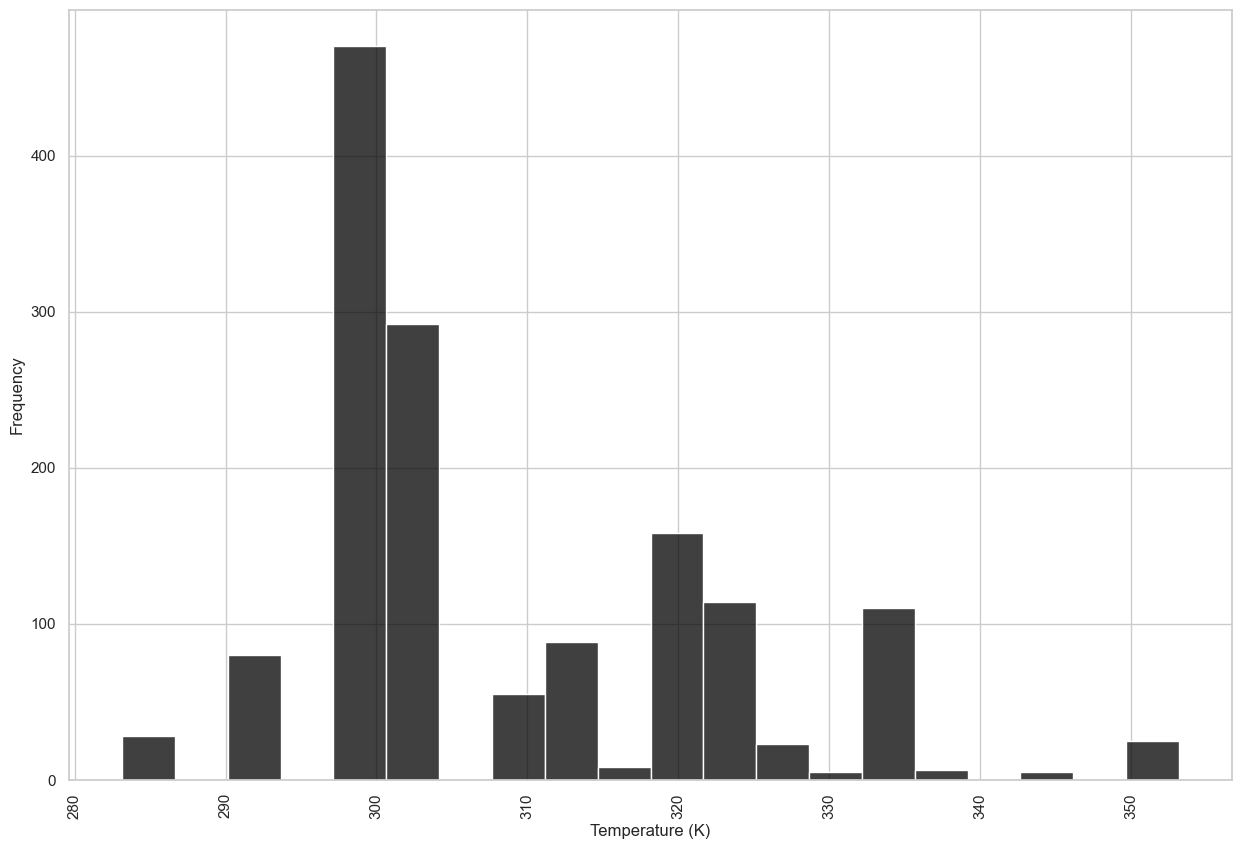

In [117]:
sns.histplot(data = phi_data, x = 'Temperature (K)', color = 'black').set(ylabel = 'Frequency')
plt.xticks(rotation = 90)
plt.show()

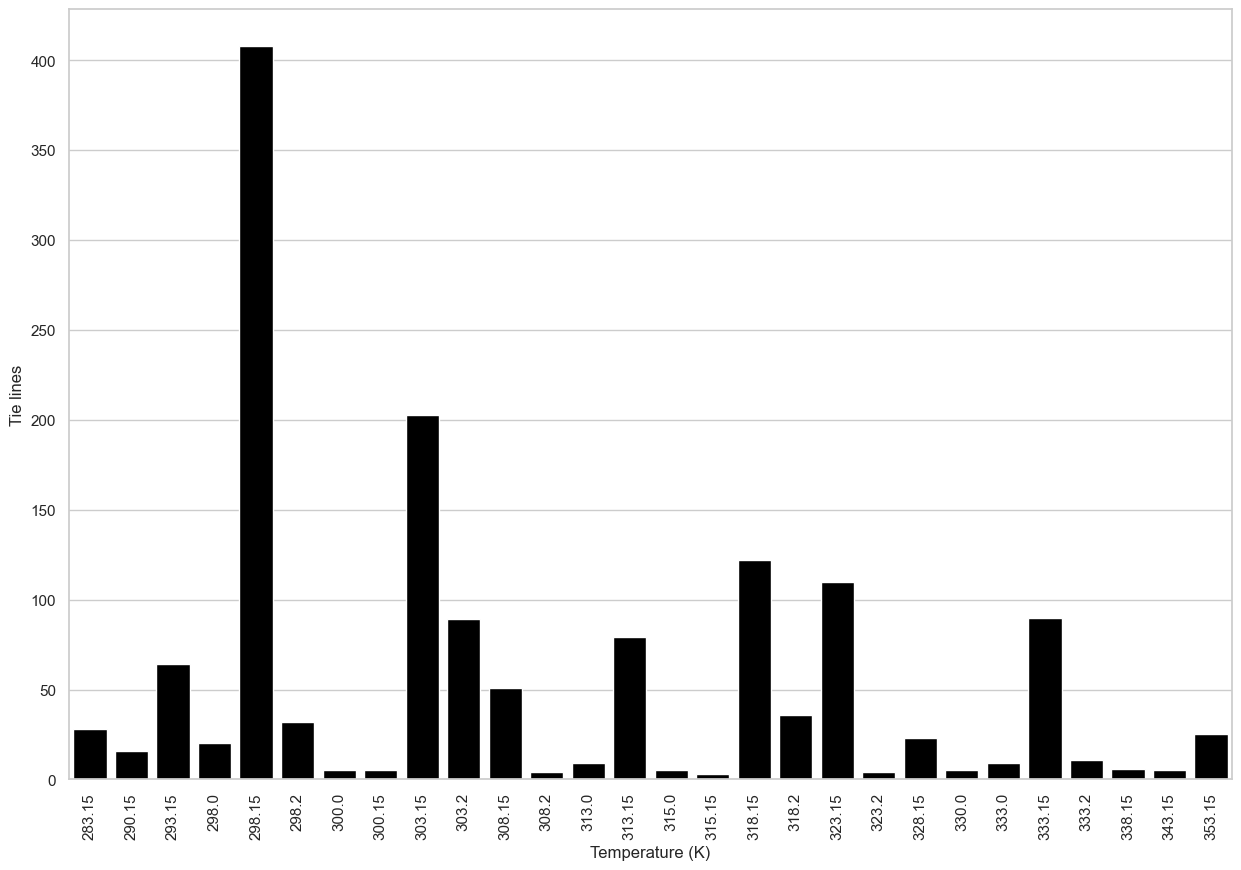

In [118]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len', color='black').set(ylabel='Tie lines')
plt.xticks(rotation = 90)
plt.show()

In [119]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,431
2,966
3,6
4,18


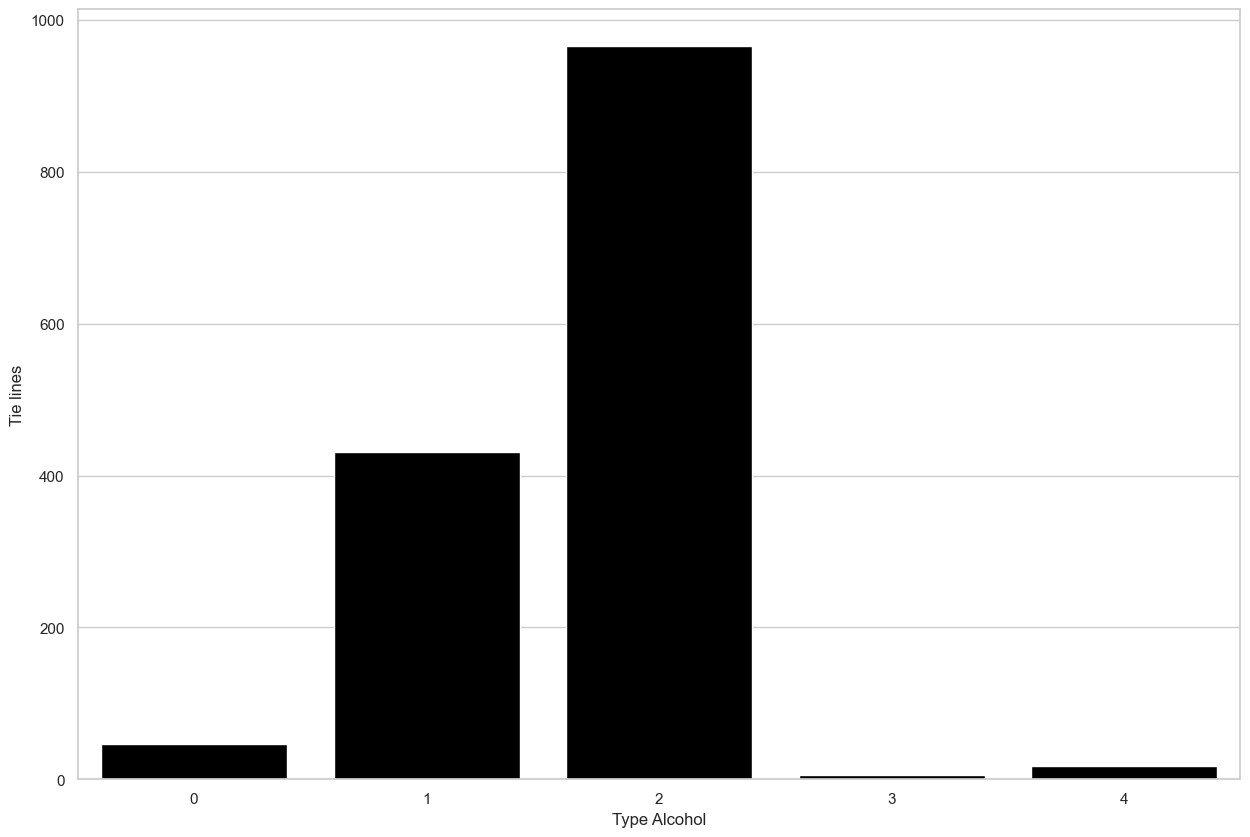

In [120]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len', color='black').set(ylabel='Tie lines')
plt.show()

In [121]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [122]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)
    
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

In [123]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)


##### 2.2 Statistical analysis of the data

In [124]:

df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1467.0,1467.0,"""1467""",1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",733.0,32.74983,null,308.490048,1.67212,0.178024,0.131576,0.360306,0.240804,0.007254,0.00111,0.023056,0.057538,0.399367,0.005744,0.135025,0.424681,0.001278,0.00068,0.024127,0.009191,0.012275,0.229089,0.580317,0.045971,0.000837,0.001506,0.022334,0.107611,NaN,NaN,NaN,0.278948,-inf,0.020075,NaN,NaN,NaN,null,NaN
"""std""",423.630735,14.862241,null,13.754783,0.604265,0.209426,0.183292,0.160971,0.228252,0.056253,0.006553,0.045024,0.118605,0.440863,0.013351,0.135914,0.408361,0.006648,0.004399,0.04839,0.032124,0.037566,0.314191,0.293656,0.110696,0.004325,0.008787,0.042786,0.217756,NaN,NaN,NaN,0.267055,NaN,0.096718,NaN,NaN,NaN,null,NaN
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-26.542169,-0.160734,-inf,-0.333333,-3.2,-0.008,-inf,null,0.0
"""25%""",367.0,23.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.3296,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379947,0.0,0.0,0.0,0.0,0.0,0.416374,null,0.005922
"""50%""",733.0,35.0,null,303.15,2.0,0.0,0.0,0.4367,0.327,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1006,0.5813,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.656,0.0031,0.0,0.0,0.0,0.0,0.0,0.0,0.495118,0.444153,0.0,0.0,0.0,0.0,0.495811,null,0.01592
"""75%""",1100.0,45.0,null,318.15,2.0,0.3637,0.3,0.475,0.4695,0.0,0.0,0.0248,0.0607,0.89617,0.00525,0.1711,0.84227,1.0000e-20,1.0000e-20,0.0264,0.0063,0.0121,0.4991,0.8424,0.0461,0.0,0.0,0.0251,0.1104,0.426625,0.377542,0.529954,0.525158,0.0,0.0,0.476923,0.525823,0.543767,null,0.051567
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.8698,0.6355,0.7005,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,1000.0,inf,1.801711,7.0050e19,0.590909,21.0,0.949069,inf,null,1.8862e19


In [125]:

df.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
u32,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[f64],f64
7,2,"""a""",293.15,2,0.4902,0.4768,0.033,0.0,0.0,0.0,0.0,0.0,0.9305,0.0219,0.0476,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0248,0.9309,0.0443,0.0,0.0,0.0,0.0,0.0,0.513857,0.49956,-3.424242,0.0,0.0,0.0,0.0,0.0,-0.803609,"[1.317465, 1.303169, … null]",1.747089
121,8,"""a""",333.15,1,0.4156,0.4249,0.1595,0.0,0.0,0.0,0.0,0.0,0.9901,0.0013,0.0086,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.011,0.9279,0.0611,0.0,0.0,0.0,0.0,0.0,0.413237,0.542845,-1.874286,0.0,0.0,0.0,0.0,0.0,-0.306068,"[0.719305, 0.848913, … null]",1.045478
235,14,"""a""",328.15,1,0.25,0.384,0.366,0.0,0.0,0.0,0.0,0.0,0.5934,0.046,0.3606,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0557,0.5807,0.3636,0.0,0.0,0.0,0.0,0.0,0.361354,0.36787,-0.8,0.0,0.0,0.0,0.0,0.0,-0.023592,"[0.384946, 0.391462, … null]",0.517605
263,17,"""a""",298.15,2,0.669,0.261,0.07,0.0,0.0,0.0,0.0,0.0,0.921,0.011,0.067,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.938,0.062,0.0,0.0,0.0,0.0,0.0,0.726384,0.730313,1.6,0.0,0.0,0.0,0.0,0.0,1.018899,"[0.292515, 0.288586, … null]",0.387401
431,27,"""aa""",318.15,1,0.4995,0.5005,0.0001,0.0,0.0,0.0,0.0,0.0,0.9952,0.0048,0.0001,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0077,0.9923,0.0001,0.0,0.0,0.0,0.0,0.0,0.498025,0.498025,NaN,0.0,0.0,0.0,0.0,0.0,NaN,"[NaN, NaN, … null]",NaN
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1110,44,"""bb""",298.15,2,0.0,0.0,0.49,0.0,0.4718,0.0,0.0102,0.028,1.0000e-20,1.0000e-20,0.0897,0.8978,1.0000e-20,1.0000e-20,0.0097,0.0028,0.0,0.0,0.9143,0.0466,0.0,0.0,0.0113,0.0278,0.0,0.0,0.514553,-0.054746,4.7180e19,0.0,0.6875,-0.008,9.4360e18,"[null, null, … 9.4360e18]",1.5098e19
1111,44,"""bb""",298.15,2,0.0,0.0,0.4498,0.0,0.5192,0.0,0.0002,0.0308,1.0000e-20,1.0000e-20,0.0836,0.9137,1.0000e-20,1.0000e-20,0.0002,0.0025,0.0,0.0,0.9253,0.0165,0.0,0.0,0.0002,0.058,0.0,0.0,0.564928,-0.018391,5.1920e19,0.0,NaN,0.49009,NaN,"[null, null, … NaN]",NaN
1303,50,"""a""",303.2,2,0.0,0.0,0.499,0.393,0.005,0.0,0.102,0.0,1.0000e-20,1.0000e-20,0.26,0.657,0.006,1.0000e-20,0.078,1.0000e-20,0.0,0.0,0.673,0.193,0.006,0.0,0.129,0.0,0.0,0.0,0.421308,0.431034,-inf,0.0,0.529412,0.0,-inf,"[null, null, … null]",NaN


In [126]:
filtered_phi_df = df.filter((pl.col('Experimental mean phi') <=1) & (pl.col('Experimental mean phi') > 0))
filtered_phi_df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1413.0,1413.0,"""1413""",1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",729.032555,32.605803,null,308.60414,1.661005,0.178883,0.132316,0.360182,0.244741,0.001081,0.001152,0.023134,0.058165,0.402853,0.005801,0.135134,0.420655,0.001323,0.000706,0.024207,0.009415,0.012461,0.229169,0.579437,0.045871,0.000865,0.001563,0.022217,0.108352,0.210027,0.168215,0.444856,0.283201,0.022613,0.020842,0.200244,0.231378,0.476626,null,0.044519
"""std""",425.789228,14.980285,null,13.815078,0.590662,0.208694,0.182492,0.157658,0.22821,0.005528,0.006674,0.045575,0.118561,0.440484,0.013434,0.136128,0.408525,0.006768,0.00448,0.048987,0.032648,0.038159,0.310115,0.289097,0.111877,0.004401,0.008948,0.043114,0.216524,0.237506,0.228083,0.187893,0.262852,0.120434,0.098468,0.320021,0.267577,0.127825,null,0.083489
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.507519,0.0,-0.8125,-0.333333,-1.0,0.0,0.063604,null,0.0
"""25%""",357.0,22.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.332,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379121,0.0,0.0,0.0,0.0,0.0,0.415288,null,0.005415
"""50%""",725.0,35.0,null,303.15,2.0,0.0,0.0,0.4321,0.348,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1005,0.5786,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.6543,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.493178,0.461234,0.0,0.0,0.0,0.0,0.492668,null,0.014766
"""75%""",1092.0,45.0,null,318.15,2.0,0.3626,0.3,0.4749,0.4721,0.0,0.0,0.0245,0.061,0.8955,0.0054,0.171,0.84,1.0000e-20,1.0000e-20,0.0253,0.0064,0.0121,0.4991,0.8355,0.0449,0.0,0.0,0.0245,0.114,0.425669,0.37537,0.528979,0.525406,0.0,0.0,0.468354,0.525406,0.538778,null,0.043806
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.7689,0.6355,0.0586,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,0.874608,2.229878,0.778746,0.888889,0.590909,2.0,0.949069,0.927951,null,0.912044


##### 2.3 Distribution of experimental PHI for each component

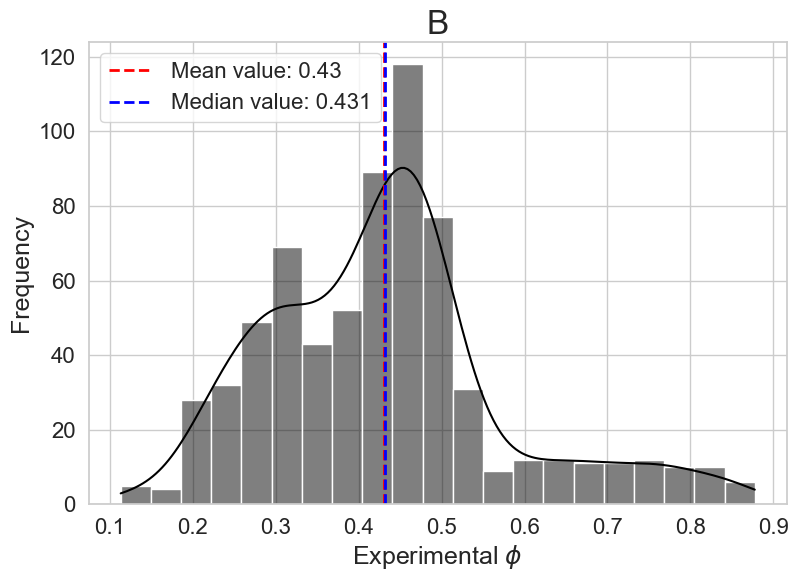

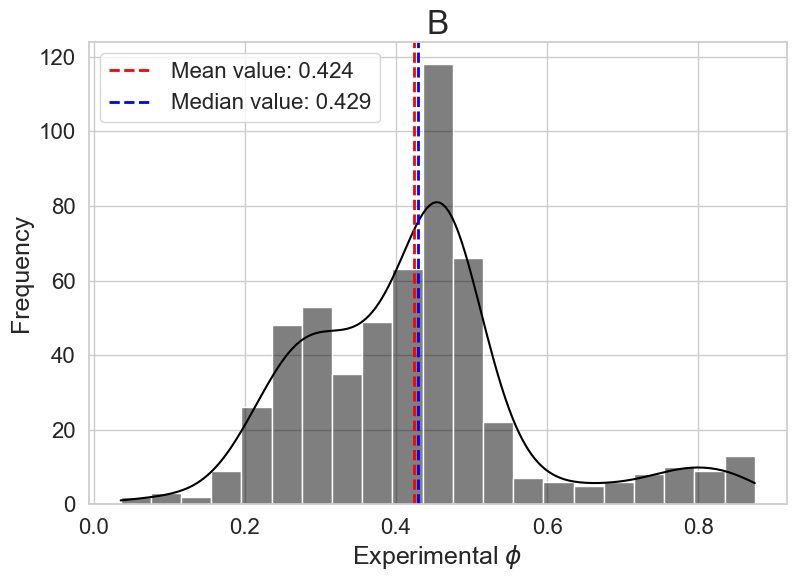

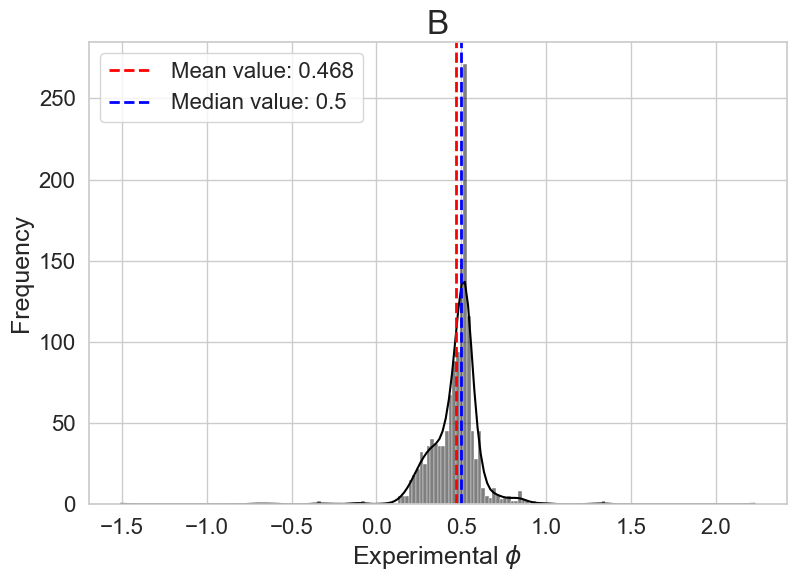

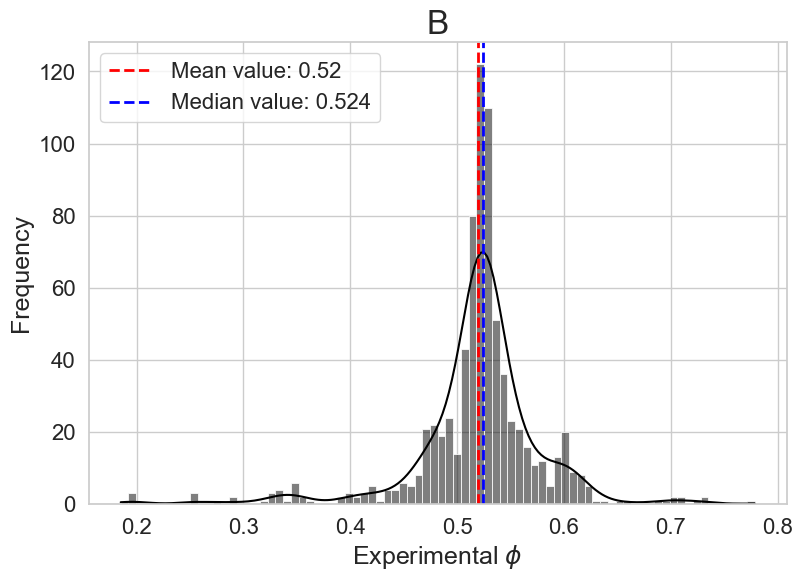

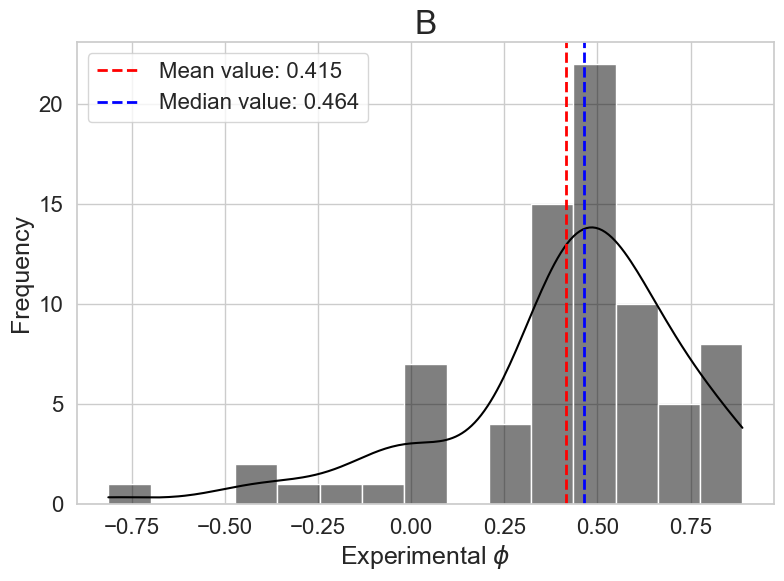

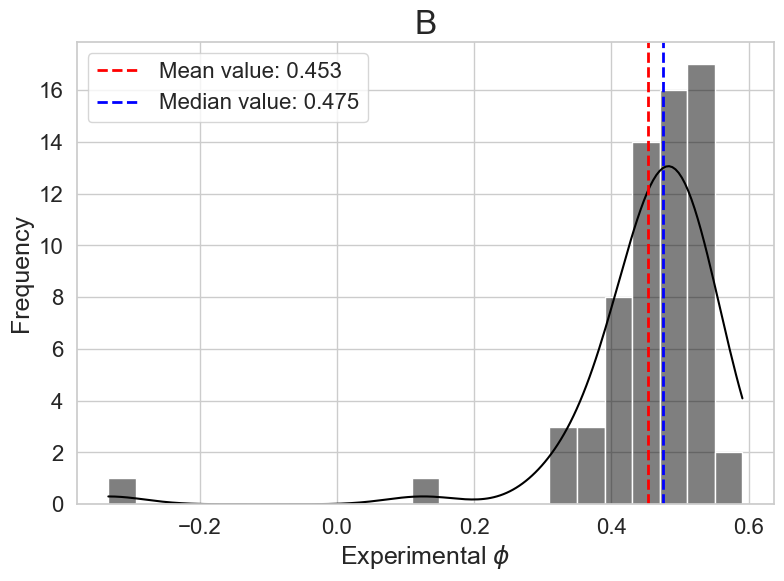

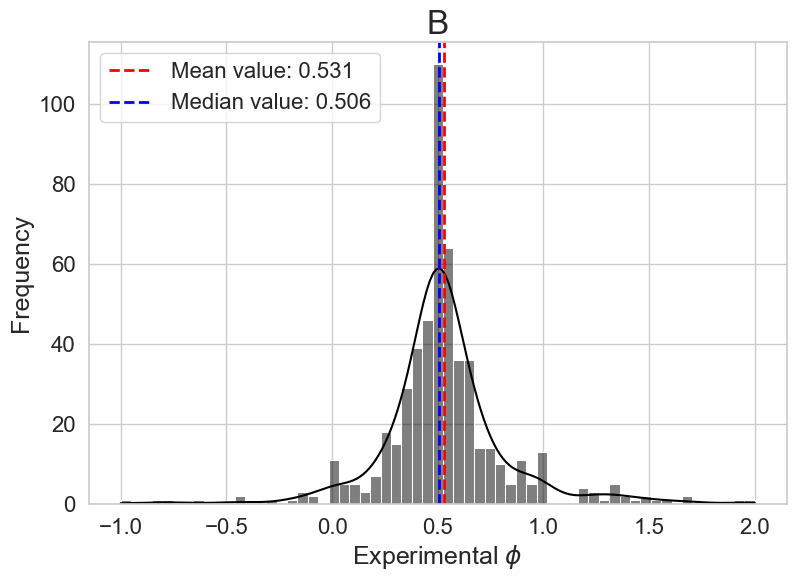

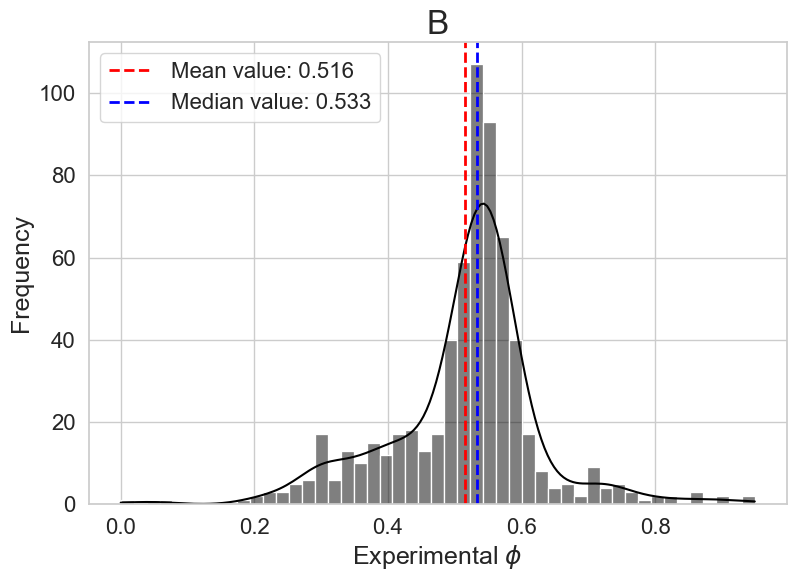

In [138]:
sns.set_theme(rc={
    'figure.figsize': (9, 6),
    'font.size': 14,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})
sns.set_style("whitegrid")

feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']

for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    
    ax = sns.histplot(x=filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), 
                      color='black', kde=True)
    ax.set_title("B", fontsize=24)
    ax.set_ylabel('Frequency', fontsize=18)
    ax.set_xlabel('Experimental $\phi$', fontsize=18)
    
    plt.axvline(mean_value, color='red', linestyle='--', linewidth=2,
                label=f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color='blue', linestyle='--', linewidth=2,
                label=f'Median value: {round(median_value, 3)}')
    
    plt.legend(loc='upper left', fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    
    # Save at 1000 DPI
    # Replace the forward slash in 'FAME/FAEE' with underscore
    safe_filename = i.rstrip('_F').replace('/', '_')
    plt.savefig(f'phi_distribution_{safe_filename}.png', 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
    
    plt.show()

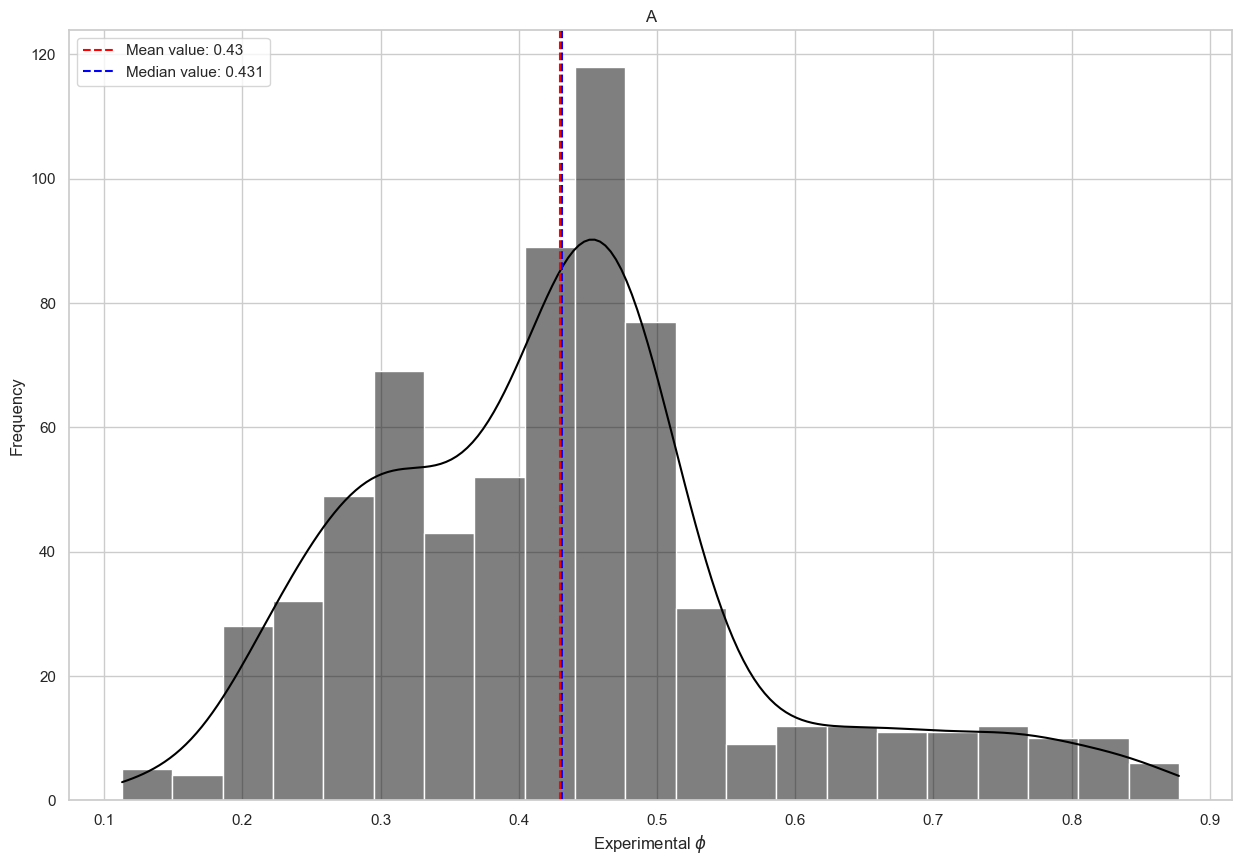

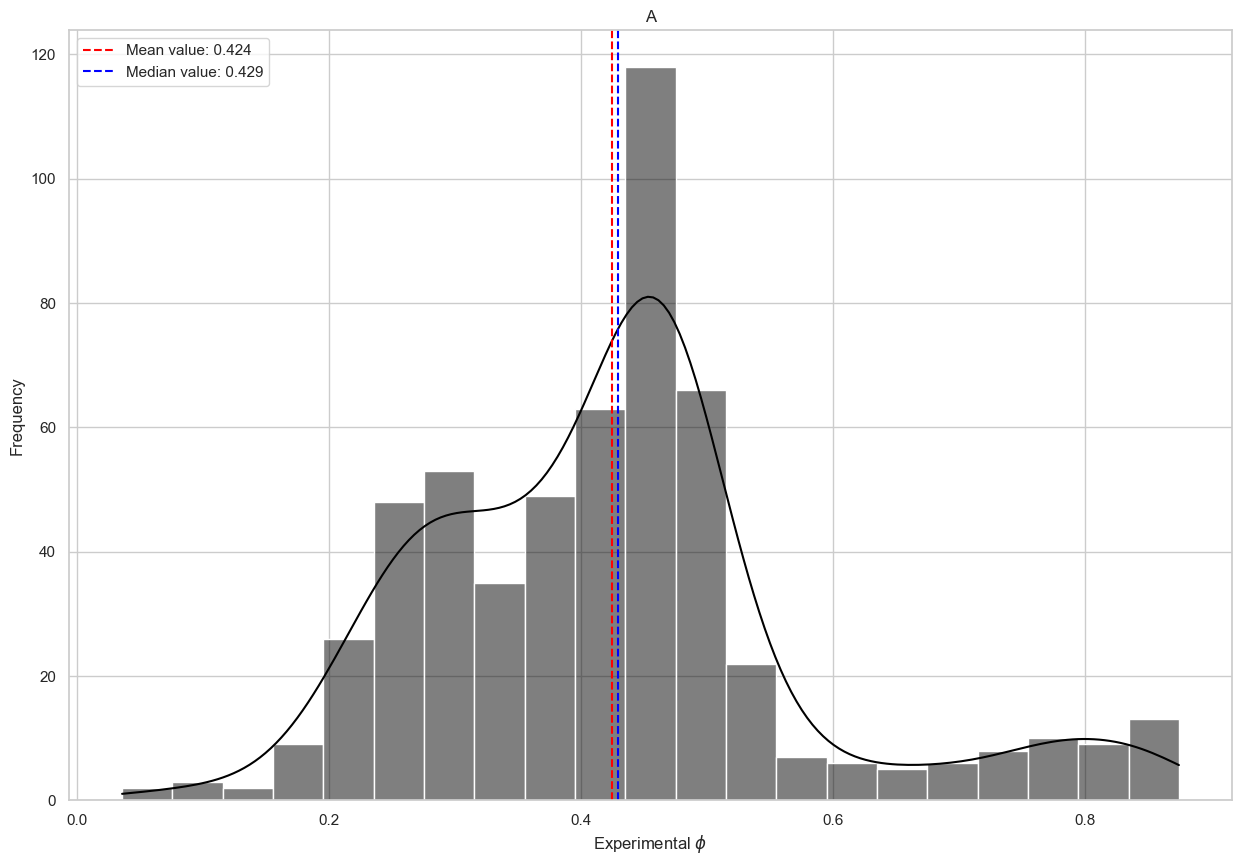

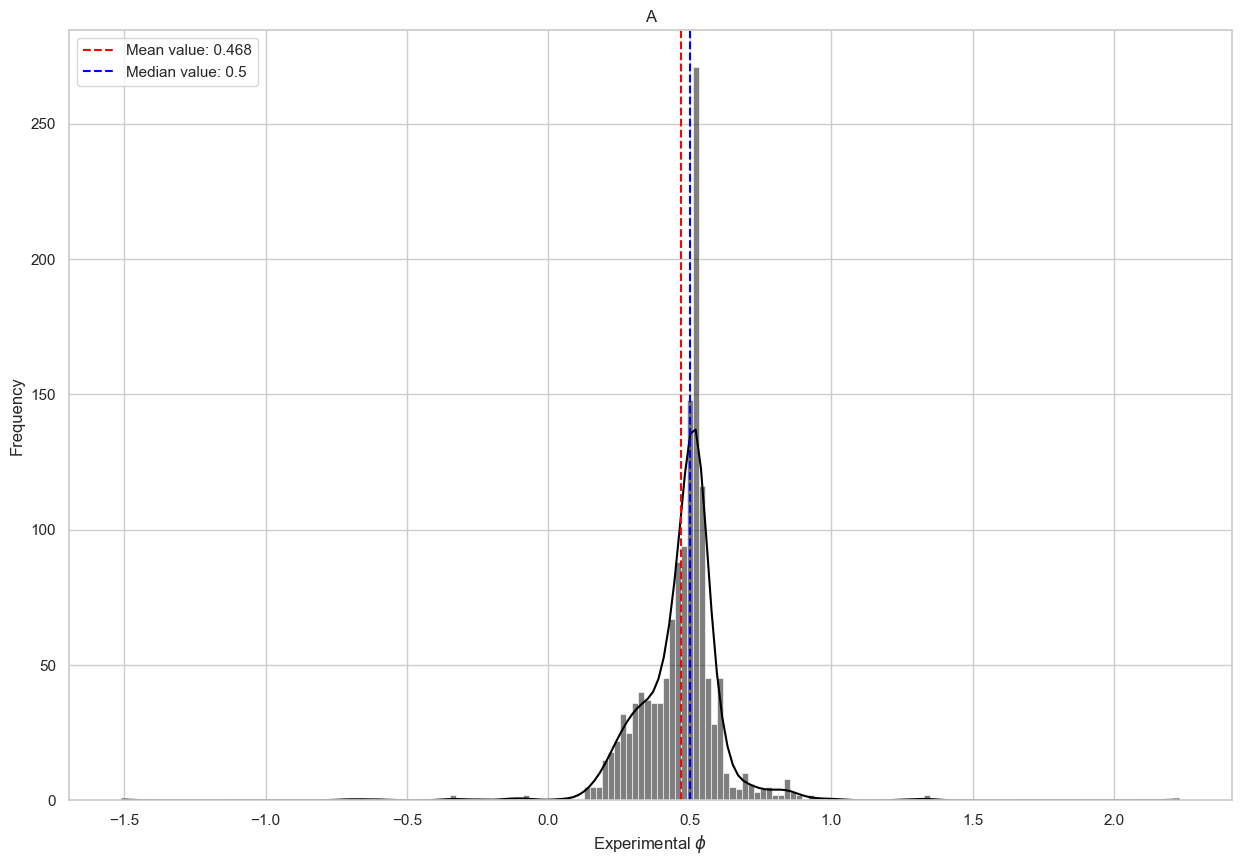

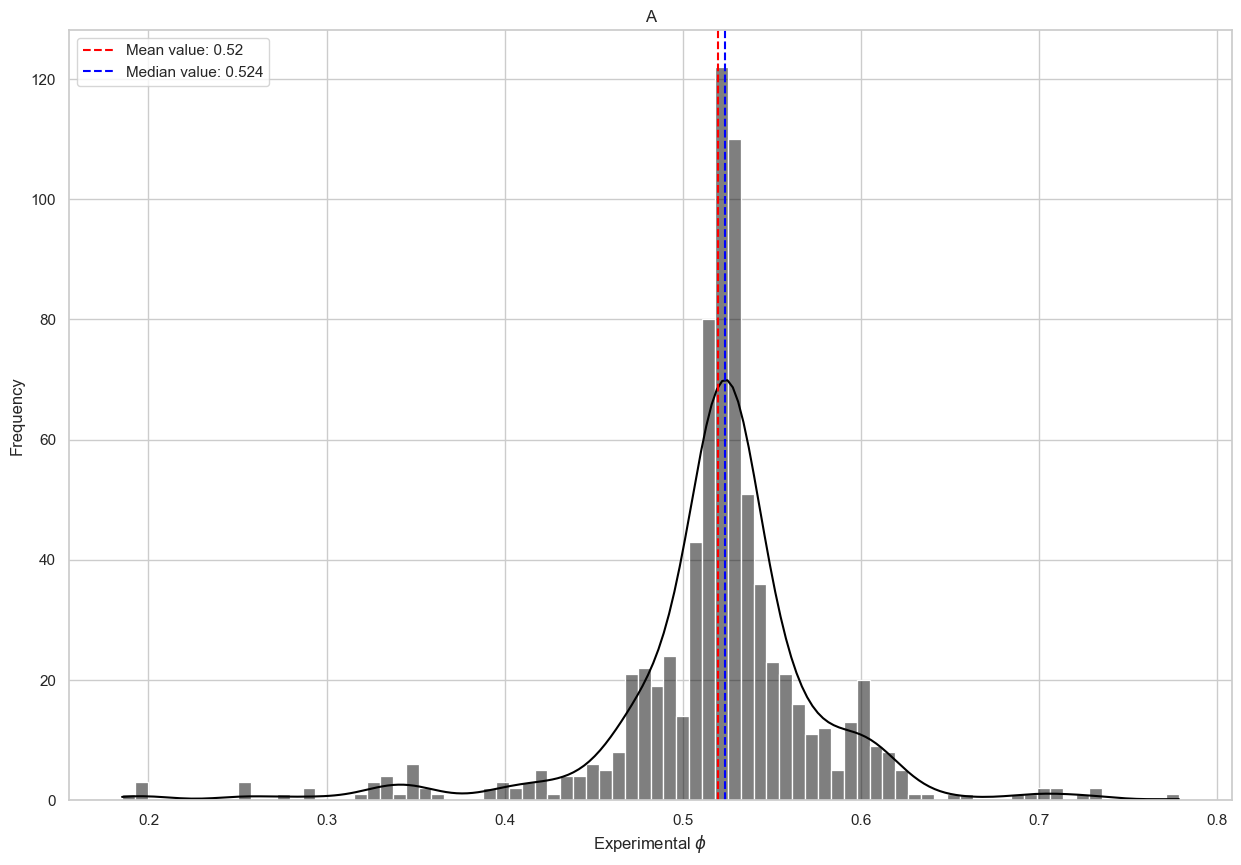

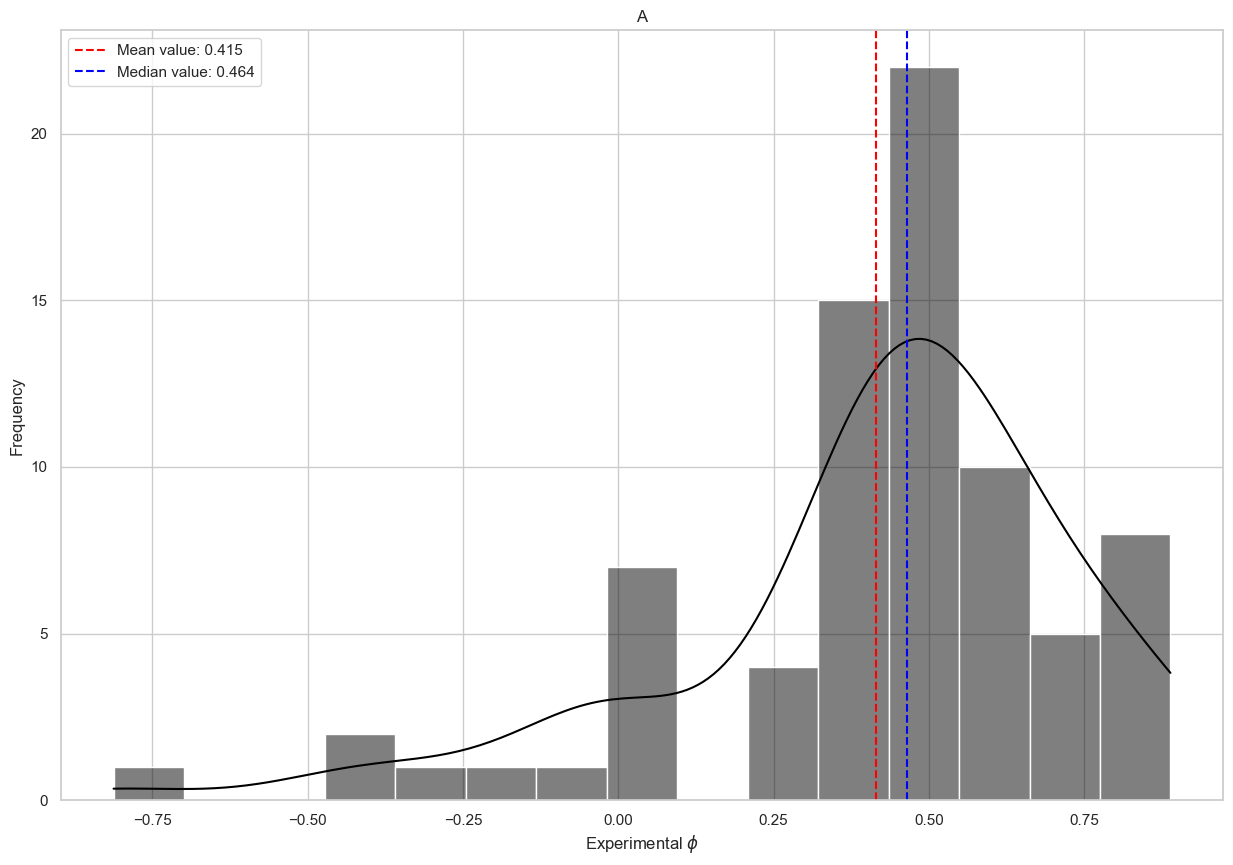

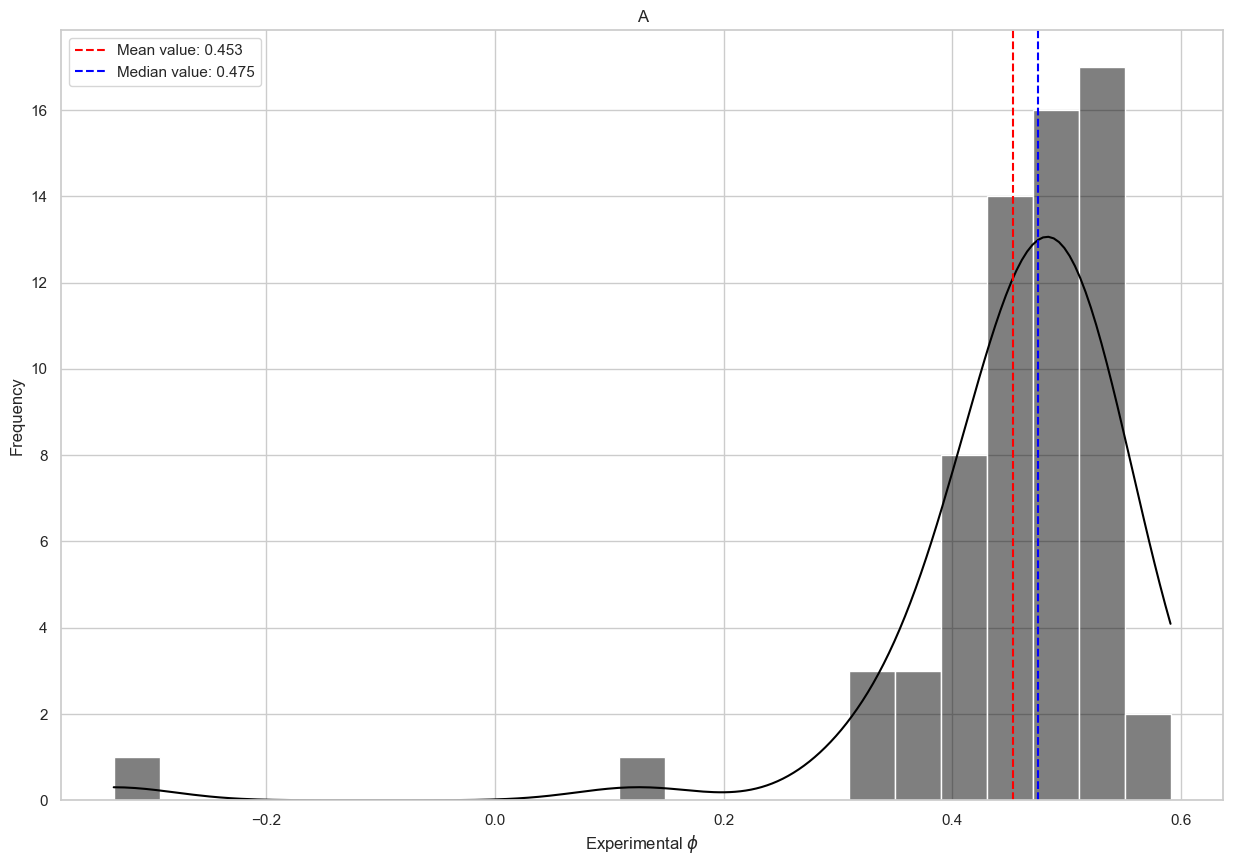

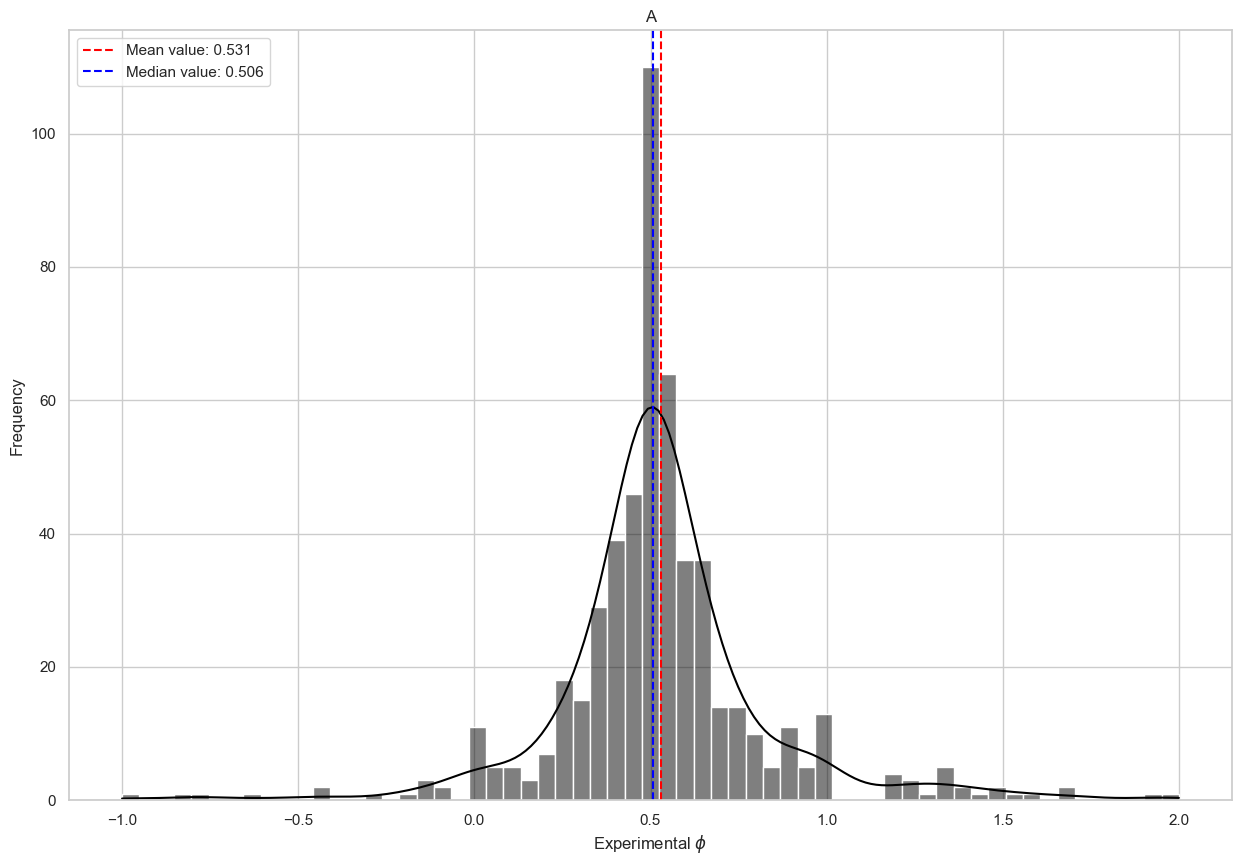

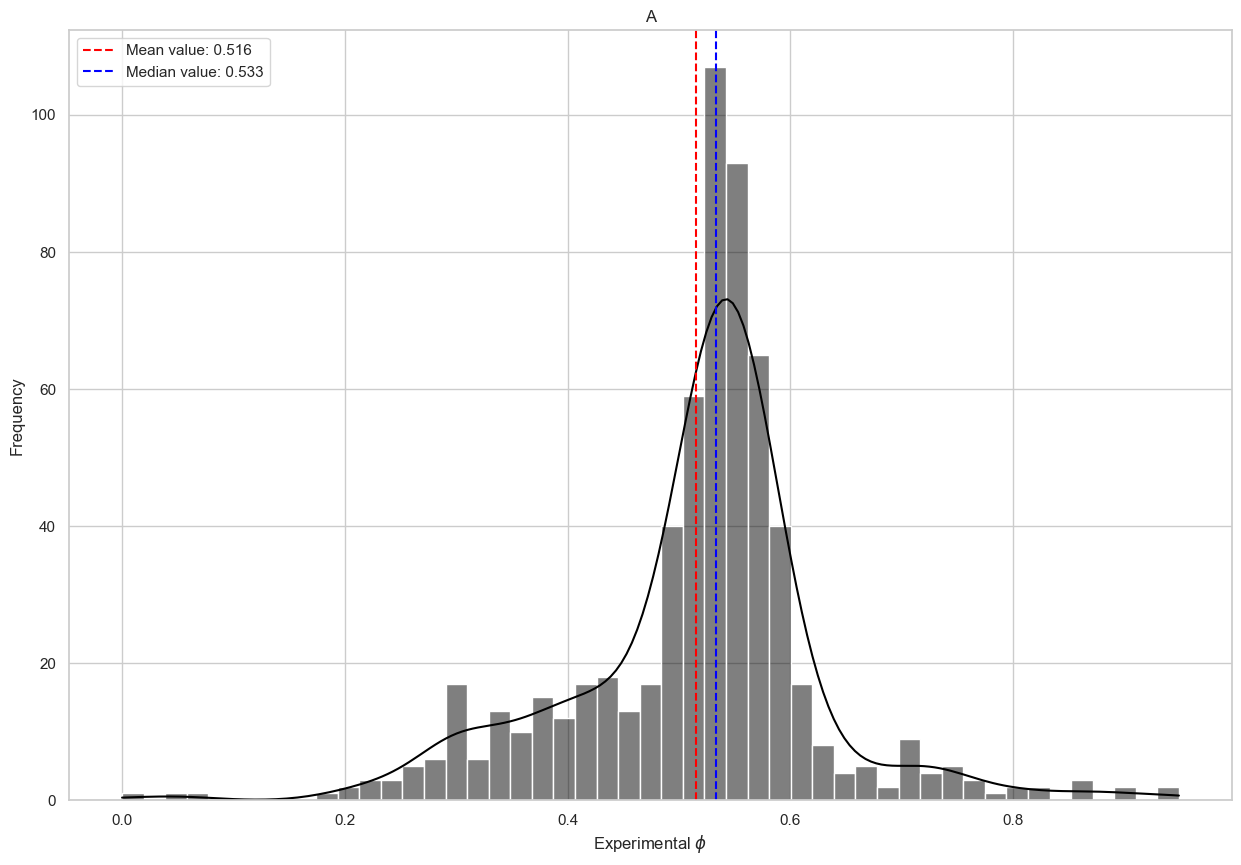

In [130]:
sns.set_theme(rc={'figure.figsize':(15, 10)})
sns.set_style("whitegrid")

feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"A", ylabel = 'Frequency', xlabel = 'Experimental $\phi$')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()
#    $\phi$ {i.rstrip('_F')}


##### 2.4 Distribution of mean experimental phi per tie line

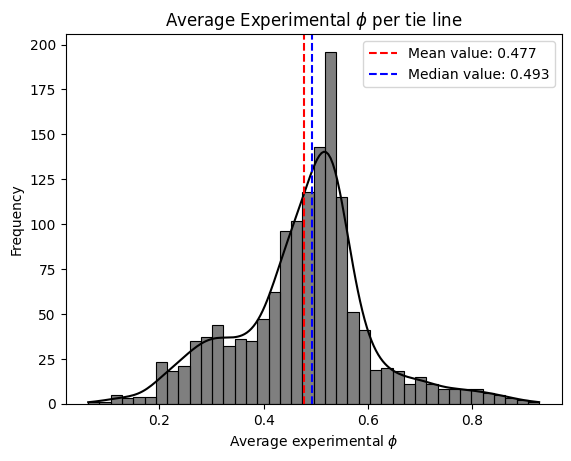

In [23]:
mean_value = filtered_phi_df.select(pl.col('Experimental mean phi')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('Experimental mean phi')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

##### 2.5 Distribution of average absolute error between the tie line experimental mean phi and each component phi 

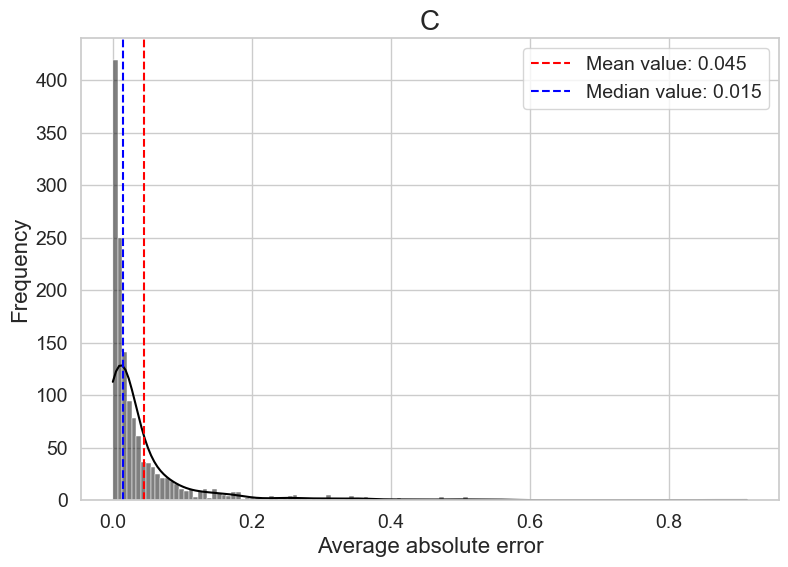

In [141]:
mean_value = filtered_phi_df.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('average_absolute_error')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.title("C")
plt.savefig("Figure_1C.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
    
plt.show()

### 3.Analysis of refined data

In [142]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data, phi_names = ExperimentalValidation(path_to_data=r'C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=i).validate_data()
    lengths.append(validated_data.shape[0])
    
    

##### 3.1 Effect of error threshold on filtered data

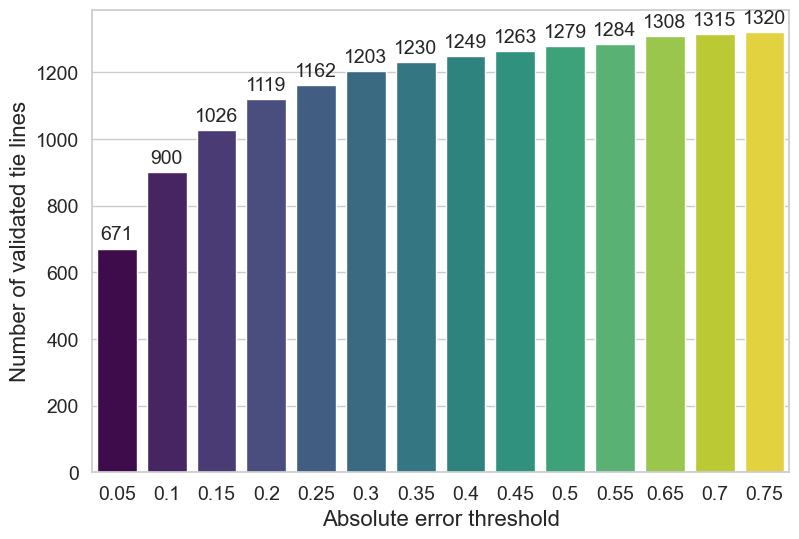

In [143]:
plt.figure(figsize=(9, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Absolute error threshold')
ax.set_ylabel('Number of validated tie lines')

plt.savefig("Figure_2.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
# Show the plot
plt.show()

##### 3.2 Statistical analysis of reconciled data and distribution of reconciled phi

In [144]:

refined_data = (pl.read_excel('data/refined_lle_data.xlsx', engine='calamine')).with_row_index()

In [145]:
refined_data.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.057055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,0.0,0.096617,0.0,0.0,0.0,0.0,0.0,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,0.0,0.0,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999


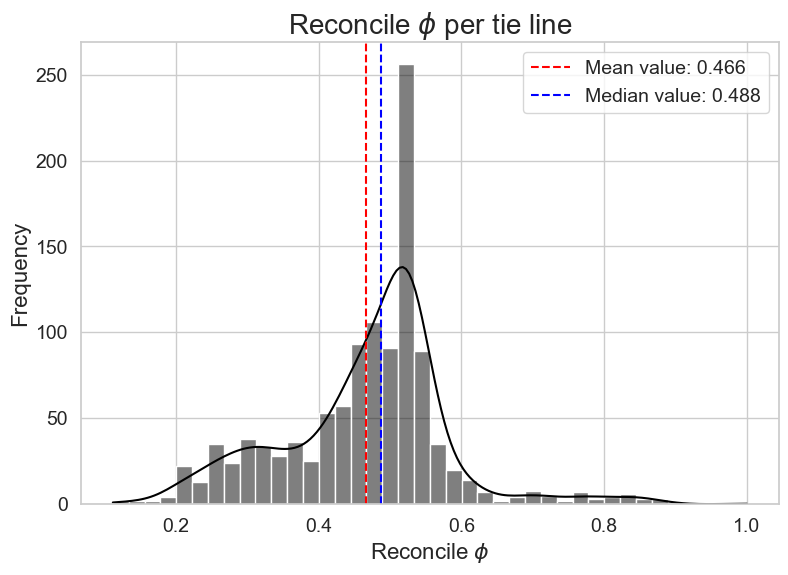

In [146]:
mean_value = refined_data.select(pl.col('Reconcile phi')).mean().to_numpy()[0][0]
median_value = refined_data.select(pl.col('Reconcile phi')).median().to_numpy()[0][0]
sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

In [147]:
refined_experimental_data = refined_data.select(pl.col(['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F',
                                                       'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 
                                                       'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']))

In [148]:

component_list = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
num_components = 8
refined_experimental_data = refined_experimental_data.with_columns( 
        
            [pl.when(pl.nth(i)==0.0)
            .then(1e-20)
            .otherwise(pl.nth(i))
            .alias(refined_experimental_data.columns[i])
            for i in range(num_components, num_components*2)]   # The parameters in the range function consider the columns with compositions of the light phase  
            
        )
        

In [149]:
refined_experimental_phi = refined_experimental_data.select(
            
            [((pl.nth(i) - pl.nth(i+num_components*2))/(pl.nth(i+num_components) - pl.nth(i+num_components*2)))
            .alias(f'phi_{component_list[i]}') 
            for i in range(0, num_components)]
        ).with_row_index()
        

In [150]:
refined_experimental_phi = refined_experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

In [151]:
refined_experimental_data = refined_experimental_data.with_row_index()

In [152]:
refined_total_data = refined_experimental_data.join(refined_experimental_phi, on = 'index')

In [153]:
refined_total_data.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1064,0.0,0.0,0.4704,0.5208,0.0088,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.177716,0.813416,0.0088,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.8999,0.0914,0.0088,0.0,0.0,0.0,0.0,0.0,0.594724,0.594724,NaN,0.0,0.0,0.0,NaN


In [154]:
refined_total_data = refined_total_data.filter(pl.col('index')!= 1064)

In [155]:
refined_total_data = refined_total_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

refined_total_data = refined_total_data.with_columns(
    refined_total_data['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

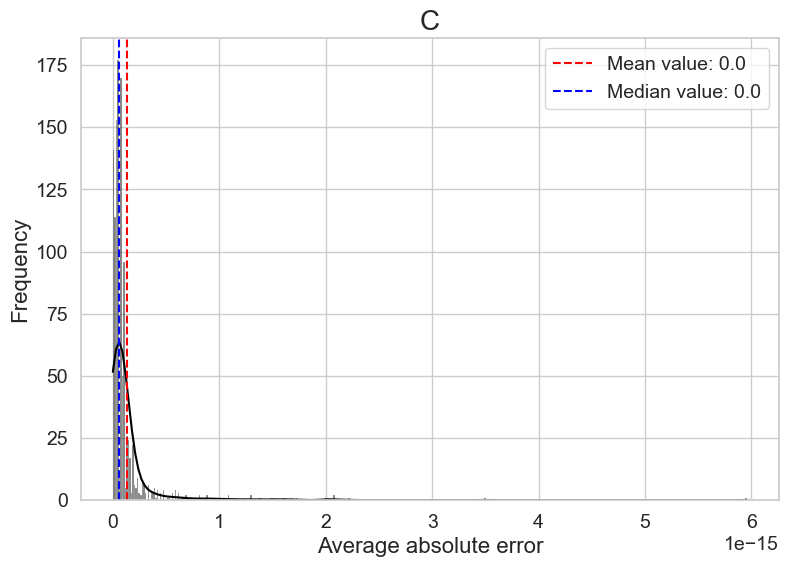

In [156]:
mean_value = refined_total_data.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = refined_total_data.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = refined_total_data.select(pl.col('average_absolute_error')).to_numpy().reshape(1133), kde = True, color='black').set(title = f'C',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.savefig("Figure_3C.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
plt.show()

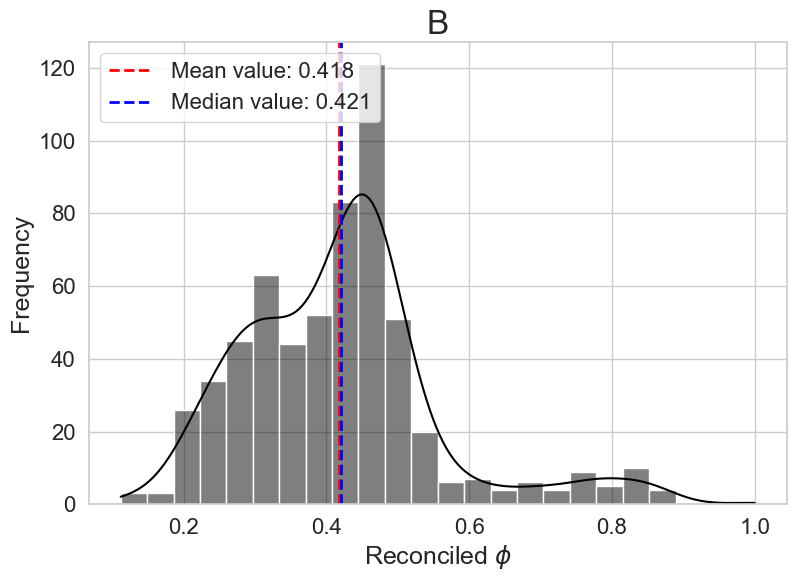

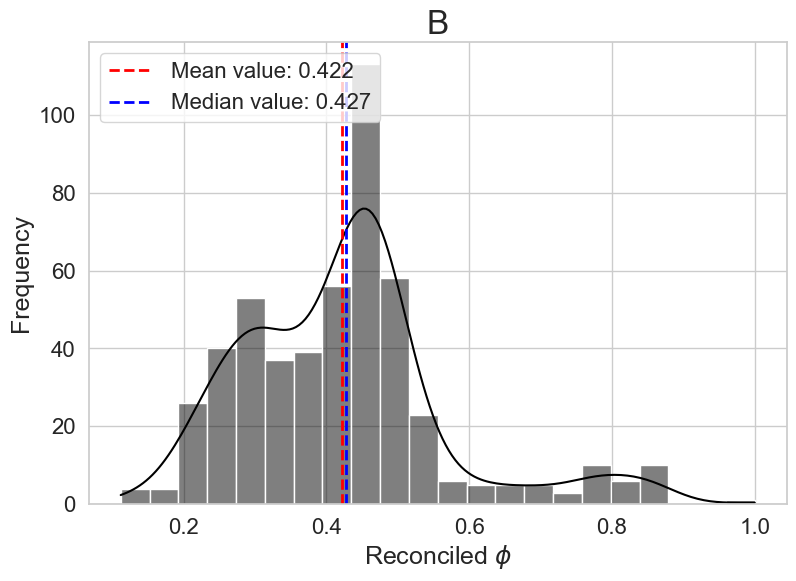

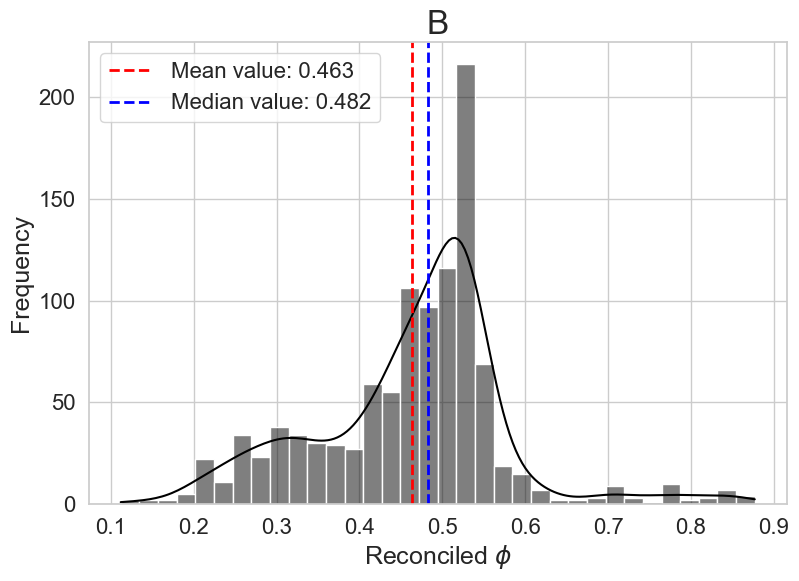

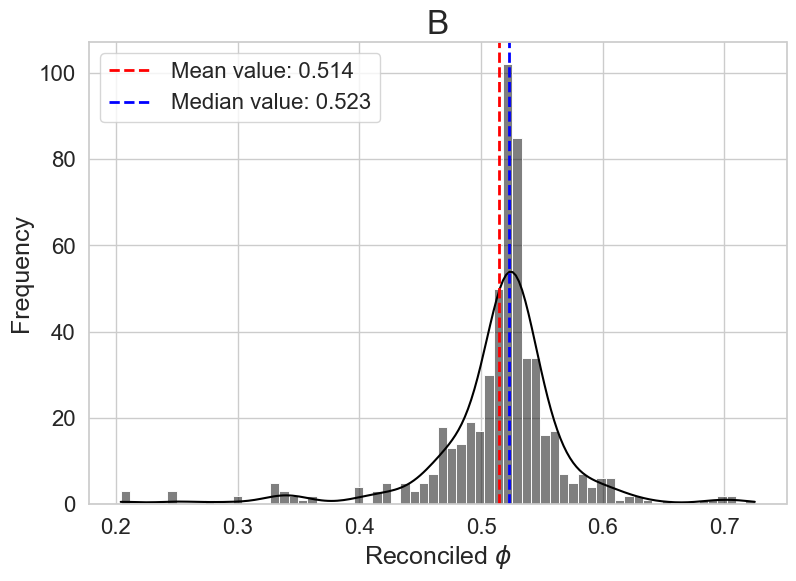

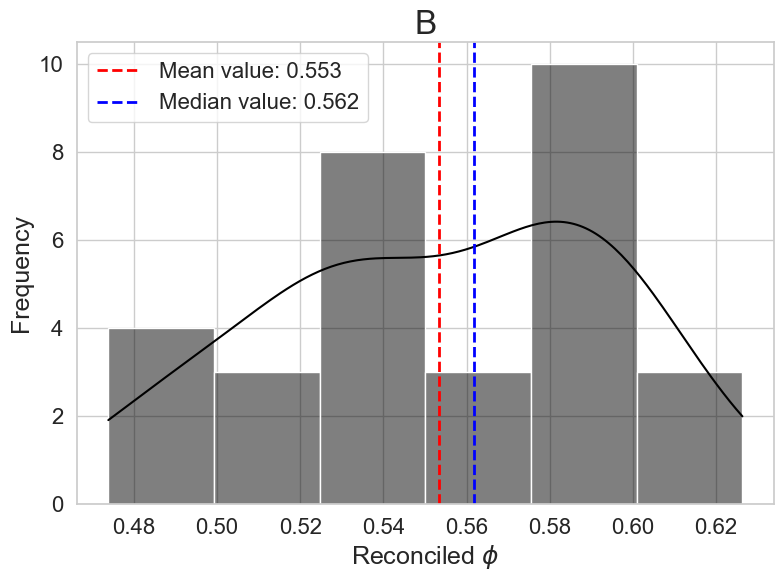

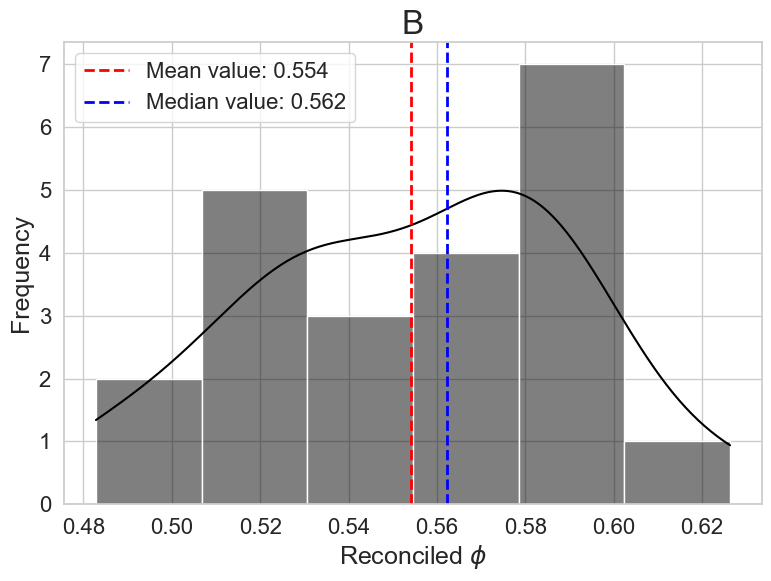

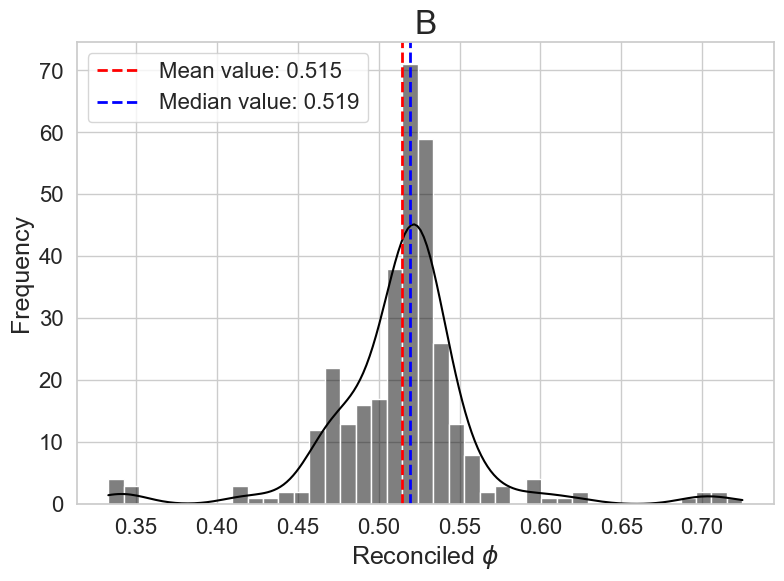

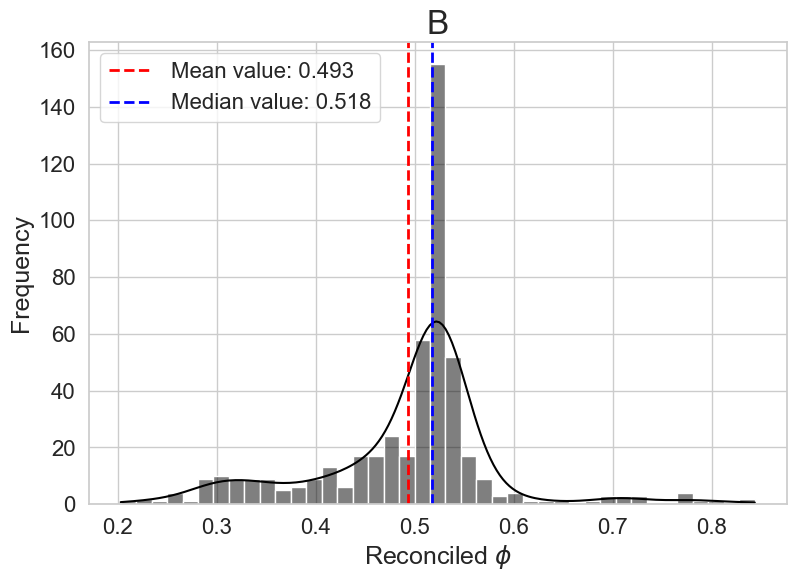

In [158]:

sns.set_theme(rc={
    'figure.figsize': (9, 6),
    'font.size': 14,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})
sns.set_style("whitegrid")


feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']

for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    
    # Create the histogram
    sns.histplot(x=filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), 
                 color='black', kde=True)
    
    # Set labels with larger fonts
    plt.title(f"B", fontsize=24)
    plt.ylabel('Frequency', fontsize=18)
    plt.xlabel('Reconciled $\phi$', fontsize=18)
    
    plt.axvline(mean_value, color='red', linestyle='--', linewidth=2,
                label=f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color='blue', linestyle='--', linewidth=2,
                label=f'Median value: {round(median_value, 3)}')
    
    plt.legend(loc='upper left', fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    
    # Create safe filename and save at 1000 DPI
    safe_filename = i.rstrip('_F').replace('/', '_')
    plt.savefig(f'reconciled_phi_distribution_{safe_filename}.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
    plt.show()

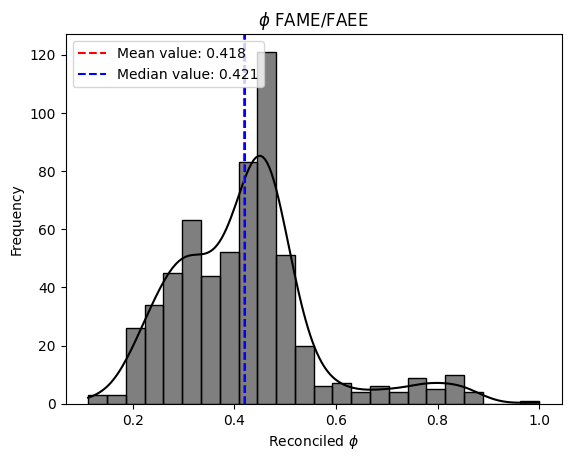

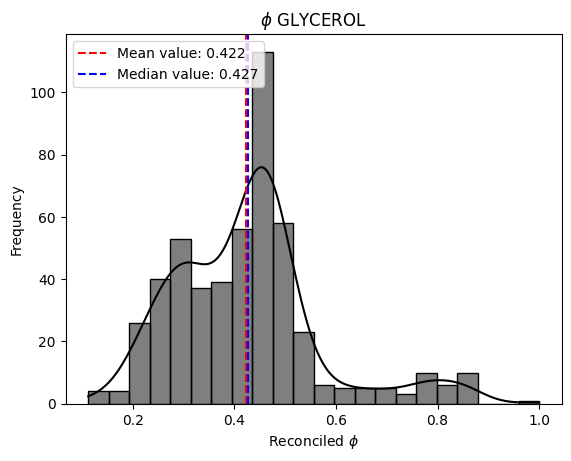

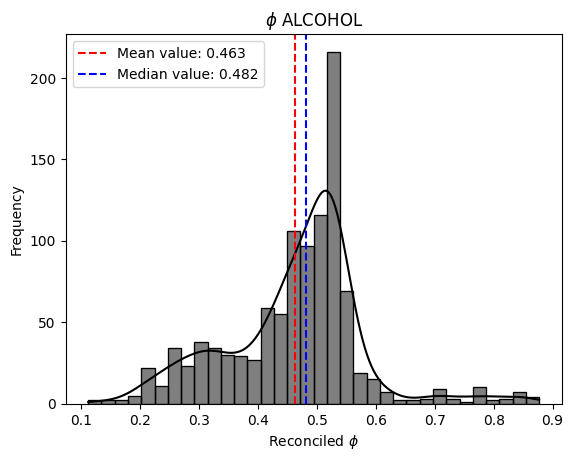

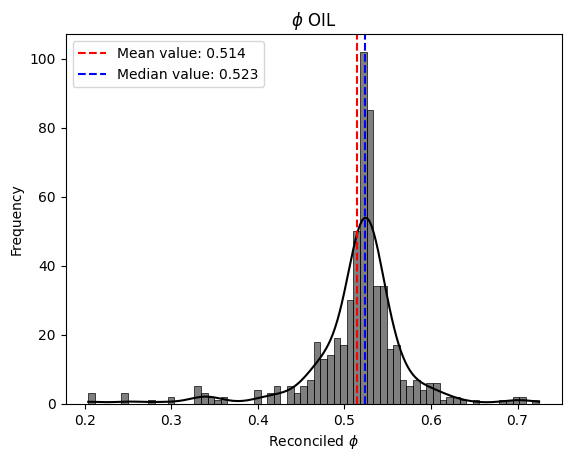

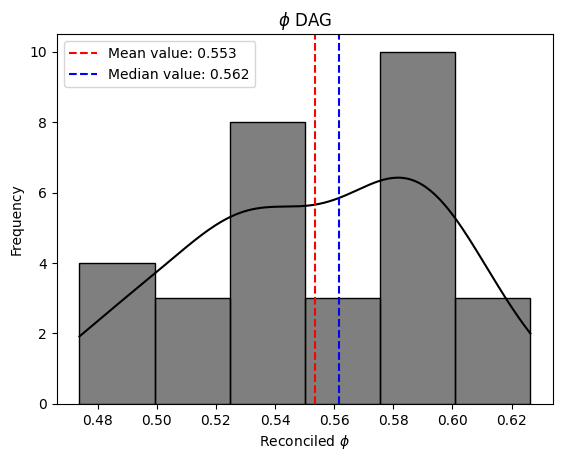

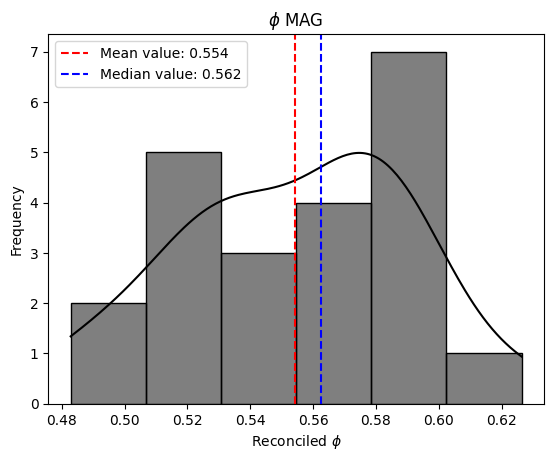

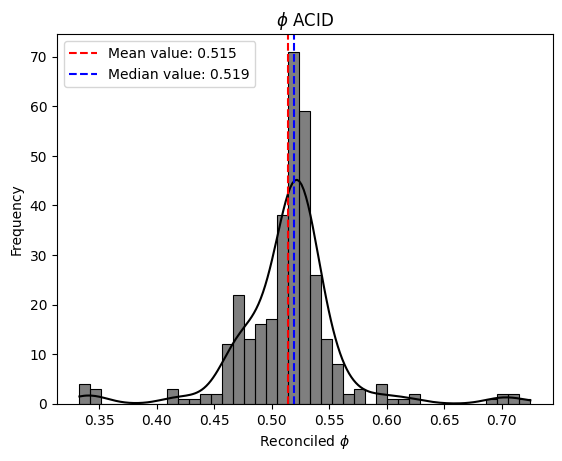

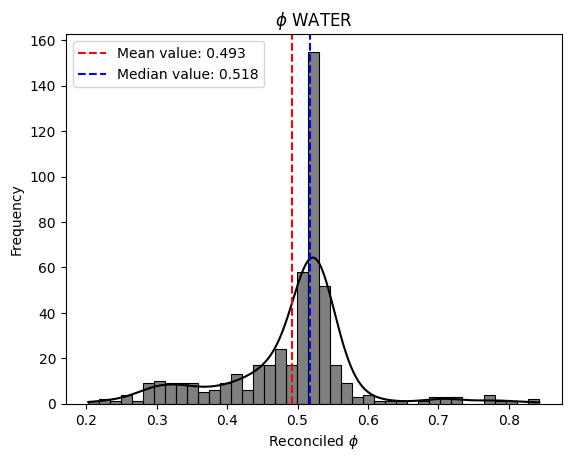

In [45]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Reconciled $\phi$')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

###  4. Source Data

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics import root_mean_squared_error

from matplotlib import cm
from scipy.interpolate import griddata

In [16]:
comps_mw = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx")
profile_coeffs_ref = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\SensitivityAnalysis\data\profile_coeffs_ref.xlsx")


In [17]:
profile_coeffs_ref = profile_coeffs_ref.filter(
    ~(pl.col("Source").str.contains("- Acid") | pl.col("Source").str.contains("- FAME")| pl.col("Source").str.contains("- MAG/DAG"))
)

In [18]:
result = comps_mw.join(
    profile_coeffs_ref.select(["Ref", "Sub Ref", "Source"]),  # Select only the columns you need from df2
    on=["Ref", "Sub Ref"],  # Join on these two columns
    how="left"  # Use left join to keep all rows from df1
)

In [19]:
results_pd = result.to_pandas()

In [20]:
def calculate_stats(df, parameters):
    mean_value = df[parameters].mean()
    std_value = df[parameters].std()
    max_value = df[parameters].max()
    min_value = df[parameters].min()

    return {"mean":mean_value, "std":std_value, "max":max_value, "min":min_value}

    
stats_fame = calculate_stats(results_pd, "MW_FAME/FAEE")
stats_oil = calculate_stats(results_pd, "MW_Oil")

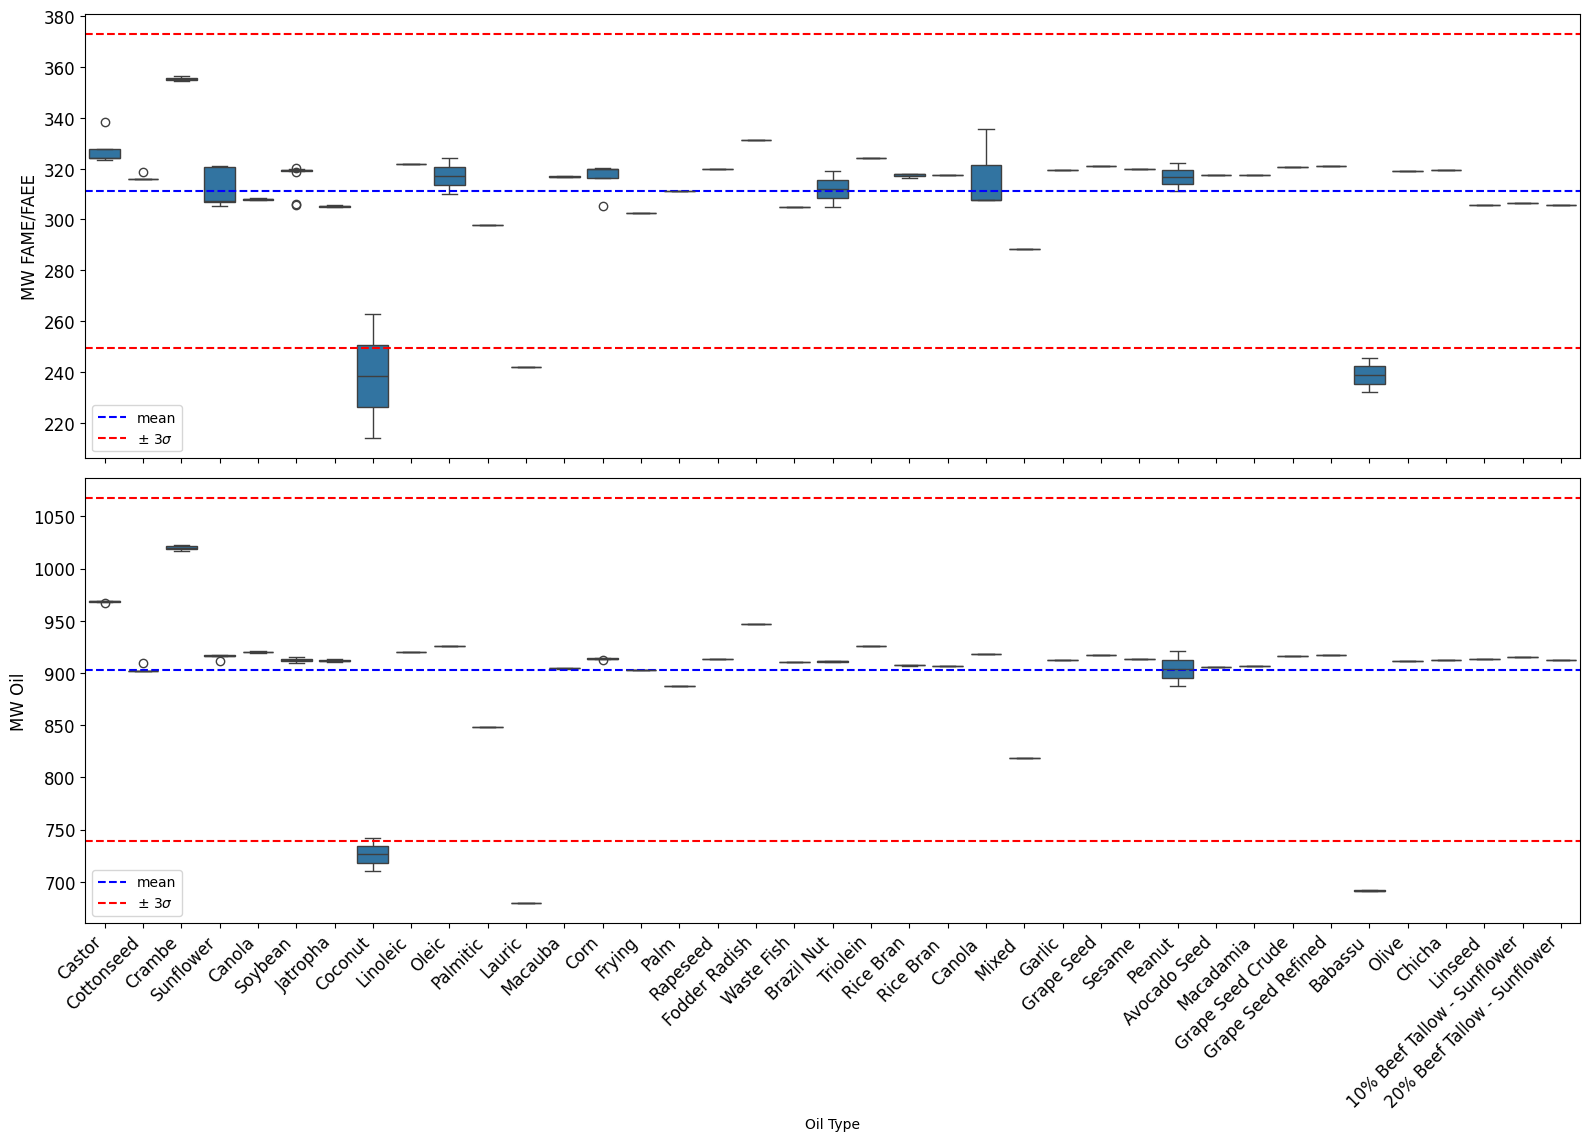

In [21]:
columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)
axes = axes.flatten()

sns.boxplot(x='Source', y="MW_FAME/FAEE", data=results_pd, ax=axes[0])
axes[0].set_xlabel('Oil Type')
axes[0].set_ylabel("MW FAME/FAEE", fontsize=12)
axes[0].axhline(y=stats_fame["mean"], color="blue", linestyle="--", label="mean")
axes[0].axhline(y=stats_fame["mean"] + stats_fame["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[0].axhline(y=stats_fame["mean"] - stats_fame["std"]*3, color="red", linestyle="--")
axes[0].tick_params(axis='both', labelsize=12)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend()

sns.boxplot(x='Source', y="MW_Oil", data=results_pd, ax=axes[1])
axes[1].set_xlabel('Oil Type')
axes[1].set_ylabel("MW Oil", fontsize=12)
axes[1].axhline(y=stats_oil["mean"], color="blue", linestyle="--", label="mean")
axes[1].axhline(y=stats_oil["mean"] + stats_oil["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[1].axhline(y=stats_oil["mean"] - stats_oil["std"]*3, color="red", linestyle="--")
axes[1].tick_params(axis='both', labelsize=12)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend()


plt.tight_layout(rect=[0, 0, 1, 0.96])
#plt.savefig(f'Figure_4.png', dpi=1000, bbox_inches='tight', facecolor='white',edgecolor='none')
    
plt.show()

##### Acid Profiles

In [160]:
acid_profiles = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\acid_profile.xlsx")

In [161]:
acid_profiles_pd = acid_profiles.to_pandas()

In [162]:
acid_profiles_pd

,Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Caproic,Caprilic,Capric,Lauric,Mirystic,Palmitic,Palmitoleic,Heptadecanoic,cis-9-heptadecenoic,Stearic,Oleic,Linoleic,Linolenic,Ricinoleic,Densipolic,Arachidic,Arachidonic,Gondoic,"cis-11,14 eicosadienoic",Behenic,Erucic,cis-13 cis-16 docosadienoic,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic,Total
0,1,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.00740,0.00000,0.0,0.0,0.00920,0.02710,0.04310,0.0032,0.8987,0.0093,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.998000
1,2,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.24500,0.00000,0.0,0.0,0.00000,0.20300,0.51200,0.0230,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.983000
2,3,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.02200,0.00000,0.0,0.0,0.01100,0.20000,0.08900,0.0480,0.0000,0.0000,0.012000,0.0,0.039,0.0,0.0180,0.556,0.006,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
3,4,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.07100,0.00000,0.0,0.0,0.03600,0.31900,0.56400,0.0040,0.0000,0.0000,0.003000,0.0,0.001,0.0,0.0010,0.000,0.002,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
4,5,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.05600,0.00000,0.0,0.0,0.03100,0.50000,0.36700,0.0410,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.005,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,55,c,Yes,No,No,0.0,0.0000,0.0000,0.00040,0.0009,0.11400,0.00080,0.0,0.0,0.05520,0.23400,0.54770,0.0353,0.0000,0.0000,0.004100,0.0,0.000,0.0,0.0045,0.000,0.000,0.0,0.0,0.0014,0.0,0.0,0.0,0.0,0.0,0.0,0.998300
121,56,a,No,No,No,0.0,0.0000,0.0000,0.00100,0.0000,0.05540,0.00100,0.0,0.0,0.04250,0.27840,0.59910,0.0040,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.981400
122,56,b,No,No,No,0.0,0.0000,0.0000,0.00467,0.0000,0.07159,0.00256,0.0,0.0,0.05385,0.29676,0.54662,0.0037,0.0000,0.0000,0.000326,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.980076
123,56,c,No,No,No,0.0,0.0000,0.0000,0.00834,0.0000,0.08778,0.00412,0.0,0.0,0.06520,0.31512,0.49414,0.0034,0.0000,0.0000,0.000652,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.978752


In [163]:
acid_profiles_pd_masked  = acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].replace(0, np.nan)

pd.set_option('display.max_columns', None)

acid_profiles_pd_masked[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].describe()


,Caproic,Caprilic,Capric,Lauric,Mirystic,Palmitic,Palmitoleic,Heptadecanoic,cis-9-heptadecenoic,Stearic,Oleic,Linoleic,Linolenic,Ricinoleic,Densipolic,Arachidic,Arachidonic,Gondoic,"cis-11,14 eicosadienoic",Behenic,Erucic,cis-13 cis-16 docosadienoic,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic
count,6.000000,5.000000,7.000000,37.000000,64.000000,114.000000,59.000000,5.000000,10.000000,104.000000,115.000000,112.000000,81.000000,5.000000,1.0000,51.000000,4.000000,8.000000,1.0000,38.000000,5.000000,4.000000,5.000000,2.000000,24.000000,2.0000,1.000,1.000,1.000,1.000,1.00
mean,0.019850,0.035560,0.310114,0.141760,0.017863,0.134168,0.018446,0.048840,0.017500,0.043136,0.374584,0.377909,0.030750,0.733700,0.0093,0.005317,0.003050,0.025700,0.0292,0.023734,0.113280,0.003350,0.002340,0.010550,0.003650,0.0466,0.011,0.046,0.119,0.359,0.12
std,0.042146,0.025639,0.471766,0.297411,0.042283,0.148235,0.032390,0.105193,0.017759,0.066846,0.257499,0.255039,0.059456,0.378801,NaN,0.004554,0.000614,0.034241,NaN,0.097292,0.247493,0.001797,0.001695,0.014354,0.004831,0.0000,NaN,NaN,NaN,NaN,NaN
min,0.001000,0.004800,0.004400,0.000200,0.000097,0.007400,0.000600,0.000500,0.000500,0.006100,0.024200,0.004100,0.000500,0.056300,0.0093,0.000326,0.002200,0.001000,0.0292,0.000500,0.001300,0.002000,0.000500,0.000400,0.000600,0.0466,0.011,0.046,0.119,0.359,0.12
25%,0.001375,0.014400,0.025300,0.001800,0.001325,0.055550,0.001150,0.000500,0.002800,0.021075,0.196900,0.114450,0.003800,0.889300,0.0093,0.002100,0.002800,0.001200,0.0292,0.001350,0.001300,0.002525,0.001000,0.005475,0.001400,0.0466,0.011,0.046,0.119,0.359,0.12
50%,0.002650,0.040800,0.045300,0.004900,0.003600,0.097100,0.003200,0.003100,0.009600,0.030500,0.278400,0.431600,0.011000,0.898700,0.0093,0.004100,0.003250,0.011200,0.0292,0.003700,0.002800,0.002700,0.002000,0.010550,0.002350,0.0466,0.011,0.046,0.119,0.359,0.12
75%,0.005200,0.051200,0.535250,0.025400,0.009650,0.154050,0.028500,0.003100,0.031975,0.040700,0.492250,0.559000,0.045900,0.912100,0.0093,0.006600,0.003500,0.039350,0.0292,0.005200,0.005000,0.003525,0.004100,0.015625,0.003925,0.0466,0.011,0.046,0.119,0.359,0.12
max,0.105800,0.066600,1.000000,1.000000,0.198400,1.000000,0.192800,0.237000,0.050100,0.487500,1.000000,1.000000,0.495441,0.912100,0.0093,0.025600,0.003500,0.100400,0.0292,0.593500,0.556000,0.006000,0.004100,0.020700,0.024800,0.0466,0.011,0.046,0.119,0.359,0.12


In [164]:
repeated_FA = (acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']] > 0).sum().sort_values(ascending=False)

repeated_FA

Oleic                          115
Palmitic                       114
Linoleic                       112
Stearic                        104
Linolenic                       81
Mirystic                        64
Palmitoleic                     59
Arachidic                       51
Behenic                         38
Lauric                          37
Gadoleic                        24
cis-9-heptadecenoic             10
Gondoic                          8
Capric                           7
Caproic                          6
Caprilic                         5
Ricinoleic                       5
Erucic                           5
Tetracosanoic                    5
Heptadecanoic                    5
Arachidonic                      4
cis-13 cis-16 docosadienoic      4
Pentadecanoic                    2
Elaidic                          2
Densipolic                       1
cis-11,14 eicosadienoic          1
9,10-methylene-hexadecanoic      1
Dihydrosterculic                 1
Paullinic           

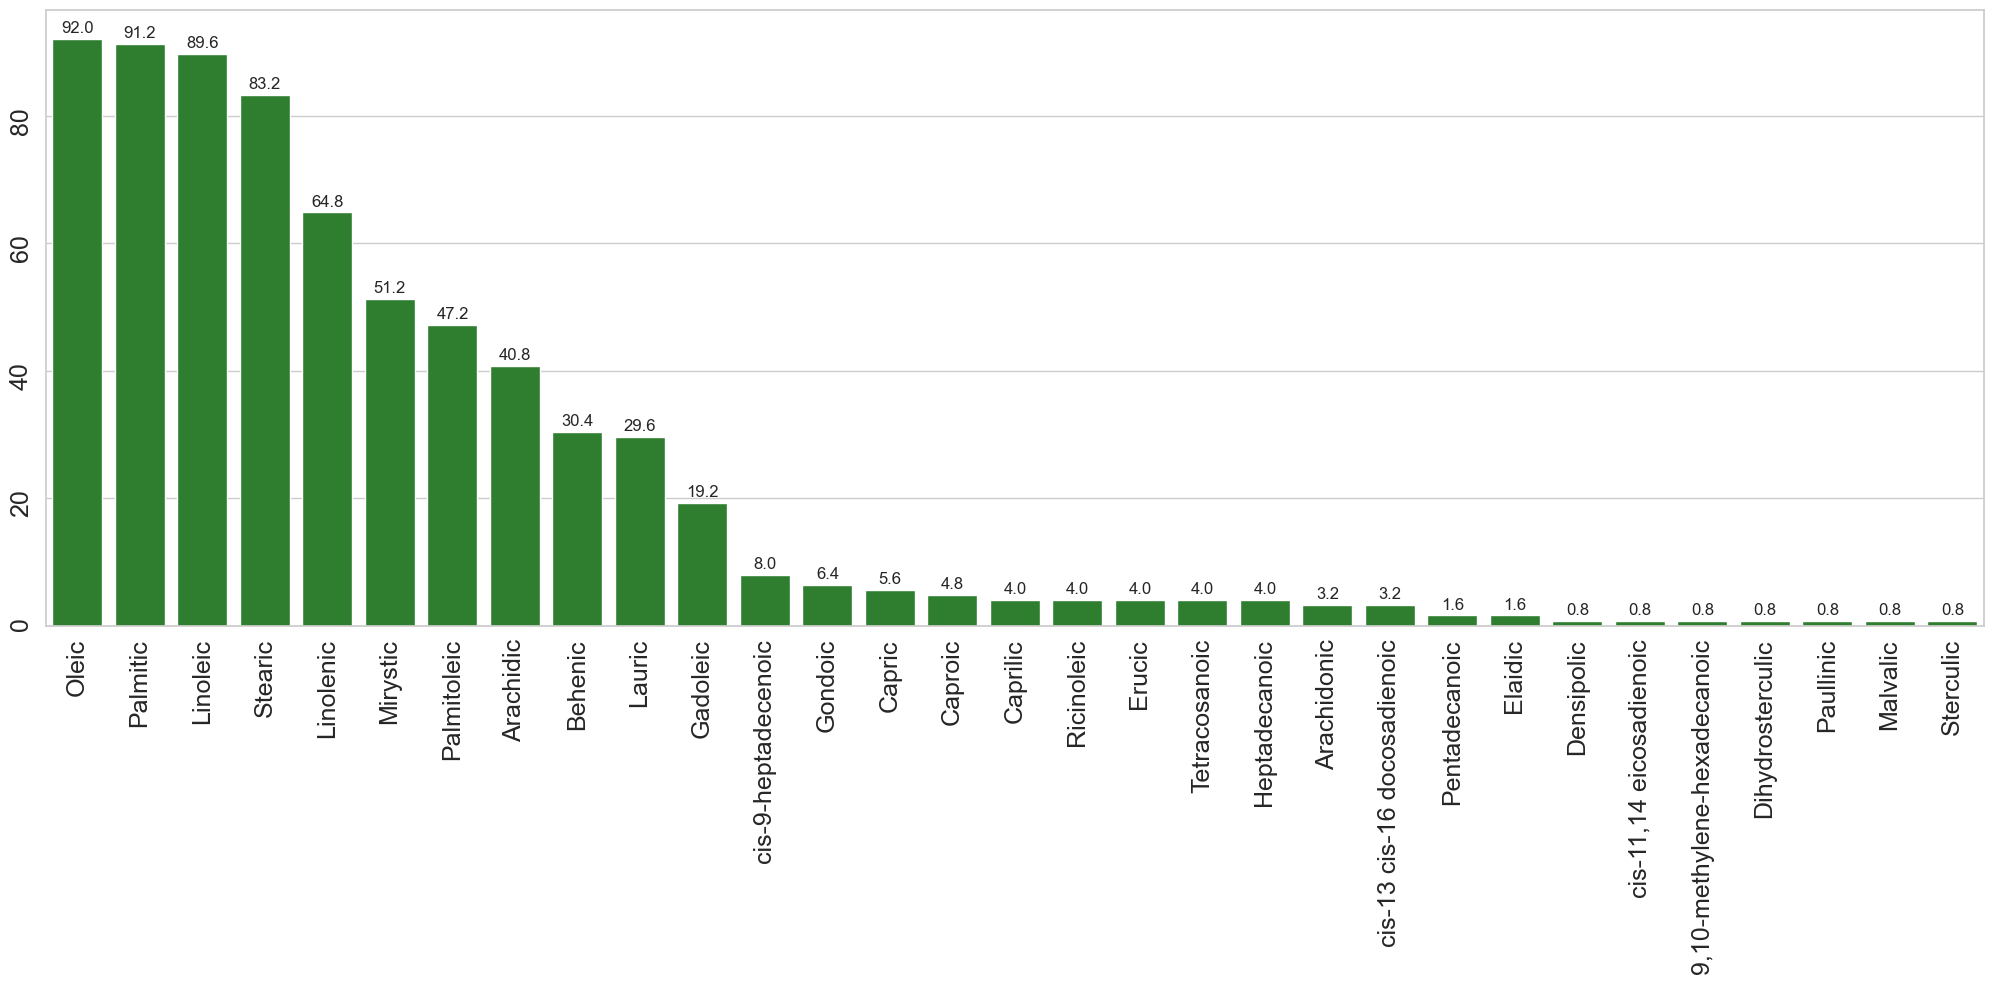

In [165]:
sns.set_theme(rc={'figure.figsize':(25,8)})
sns.set_style("whitegrid")
# Create barplot
ax = sns.barplot(repeated_FA/125*100, color="forestgreen")

# Add value labels
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}',
        ha='center',
        va='bottom'
    )
    
plt.xticks(rotation=90, fontsize=18)
plt.yticks(rotation=90, fontsize=18)

plt.show()

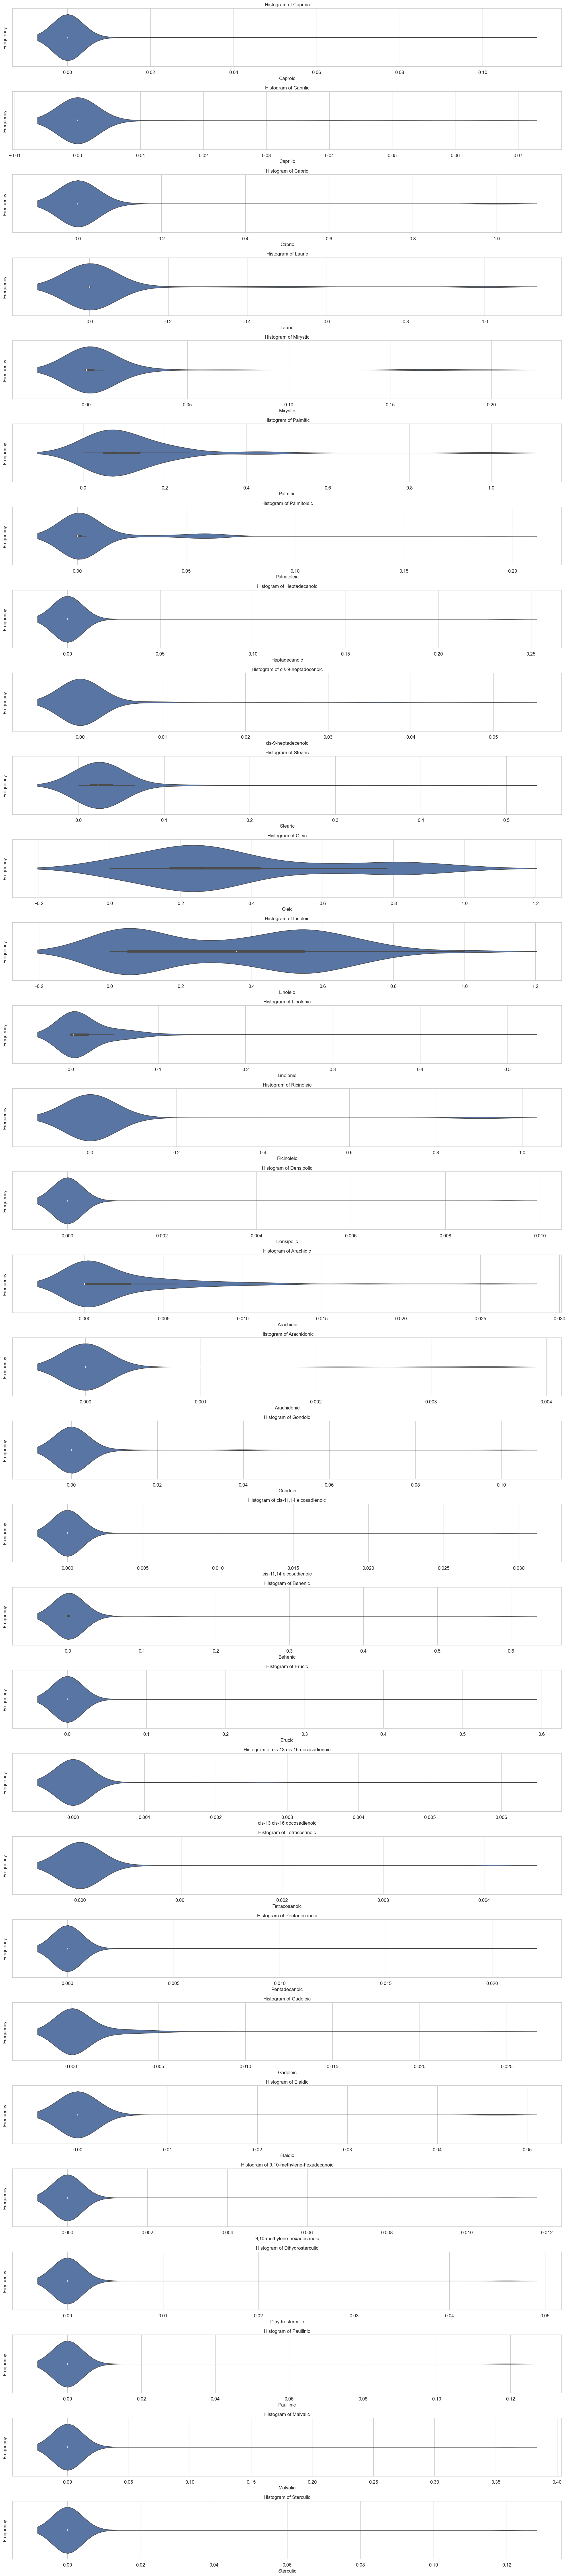

In [166]:
columns_to_plot = ['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']

# Create subplots
fig, axes = plt.subplots(len(columns_to_plot), 1, figsize=(20, 90))

# If only one column, wrap axis in a list for consistency
if len(columns_to_plot) == 1:
    axes = [axes]

# Plot each histogram
for i, col in enumerate(columns_to_plot):
    sns.violinplot(data=acid_profiles_pd, x=col,  ax=axes[i])
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

##### Equilibrium data

In [167]:

df = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\SensitivityAnalysis\data\profile_coeffs_ref.xlsx")

In [168]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [169]:
filtered_df
with pl.Config(tbl_rows=len(filtered_df), tbl_cols=-1):
    print(filtered_df)

shape: (83, 11)
┌─────┬─────┬──────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────┬─────────┐
│ Ref ┆ Sub ┆ MAG/DAG  ┆ Additio ┆ Acid    ┆ Type    ┆ m       ┆ n       ┆ p       ┆ b   ┆ Source  │
│ --- ┆ Ref ┆ Profile? ┆ nal     ┆ mix Pro ┆ Alcohol ┆ ---     ┆ ---     ┆ ---     ┆ --- ┆ ---     │
│ i64 ┆ --- ┆ ---      ┆ FAME    ┆ file?   ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆ i64 ┆ str     │
│     ┆ str ┆ str      ┆ Profile ┆ ---     ┆ i64     ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ?       ┆ str     ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ---     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ str     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
╞═════╪═════╪══════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════╪═════════╡
│ 1   ┆ a   ┆ No       ┆ No      ┆ No      ┆ 1       ┆ 12.9912 ┆ 1.04369 ┆ 

In [170]:
filtered_df.filter(pl.col("Source")=="Palm")

Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Type Alcohol,m,n,p,b,Source
i64,str,str,str,str,i64,f64,f64,f64,i64,str
20,"""a""","""No""","""No""","""No""",2,13.851386,0.587797,0.0,1,"""Palm"""
34,"""a""","""No ""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""
34,"""b""","""No""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""


In [171]:
stats_df = filtered_df.group_by('Source').agg([
    # For column 'm'
    pl.col('m').min().alias('m_min'),
    pl.col('m').quantile(0.25).alias('m_q25'),
    pl.col('m').median().alias('m_median'),
    pl.col('m').quantile(0.75).alias('m_q75'),
    pl.col('m').max().alias('m_max'),
    pl.col('m').mean().alias('m_mean'),
    
    # For column 'n'
    pl.col('n').min().alias('n_min'),
    pl.col('n').quantile(0.25).alias('n_q25'),
    pl.col('n').median().alias('n_median'),
    pl.col('n').quantile(0.75).alias('n_q75'),
    pl.col('n').max().alias('n_max'),
    pl.col('n').mean().alias('n_mean'),
    
    # For column 'p'
    pl.col('p').min().alias('p_min'),
    pl.col('p').quantile(0.25).alias('p_q25'),
    pl.col('p').median().alias('p_median'),
    pl.col('p').quantile(0.75).alias('p_q75'),
    pl.col('p').max().alias('p_max'),
    pl.col('p').mean().alias('p_mean'),
    
])

with pl.Config(tbl_rows=len(stats_df), tbl_cols=-1):
    print(stats_df)

shape: (39, 19)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Sou ┆ m_m ┆ m_q ┆ m_m ┆ m_q ┆ m_m ┆ m_m ┆ n_m ┆ n_q ┆ n_m ┆ n_q ┆ n_m ┆ n_m ┆ p_m ┆ p_q ┆ p_m ┆ p_q ┆ p_m ┆ p_m │
│ rce ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean │
│ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- │
│ str ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 │
│     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ Gra ┆ 12. ┆ 12. ┆ 12. ┆ 12. ┆ 12. ┆ 12. ┆ 1.4 ┆ 1.4 ┆ 1.4 ┆ 1.4 ┆ 1.4 ┆ 1.4 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 │
│ pe  ┆ 886 ┆ 886 ┆ 886 ┆ 886 ┆ 886 ┆ 886 ┆ 880 ┆ 880 ┆ 

In [172]:
count_values = filtered_df.group_by('Source').agg(
    pl.col('m').count().alias('m_count')
)

count_values = count_values.sort(by="m_count", descending=True)

with pl.Config(tbl_rows=len(count_values)):
    print(count_values)

shape: (39, 2)
┌─────────────────────────────┬─────────┐
│ Source                      ┆ m_count │
│ ---                         ┆ ---     │
│ str                         ┆ u32     │
╞═════════════════════════════╪═════════╡
│ Soybean                     ┆ 13      │
│ Sunflower                   ┆ 7       │
│ Cottonseed                  ┆ 5       │
│ Castor                      ┆ 4       │
│ Corn                        ┆ 4       │
│ Canola                      ┆ 3       │
│ Palm                        ┆ 3       │
│ Rice Bran                   ┆ 3       │
│ Canola                      ┆ 3       │
│ Babassu                     ┆ 2       │
│ Oleic                       ┆ 2       │
│ Crambe                      ┆ 2       │
│ Peanut                      ┆ 2       │
│ Brazil Nut                  ┆ 2       │
│ Jatropha                    ┆ 2       │
│ Coconut                     ┆ 2       │
│ Macauba                     ┆ 2       │
│ Rice Bran                   ┆ 1       │
│ Avocado Seed     

In [173]:
df_pandas = filtered_df.to_pandas()

In [14]:
def calculate_stats(df, parameters):
    mean_value = df[parameters].mean()
    std_value = df[parameters].std()
    max_value = df[parameters].max()
    min_value = df[parameters].min()

    return {"mean":mean_value, "std":std_value, "max":max_value, "min":min_value}

    
stats_m = calculate_stats(df_pandas, "m")
stats_n = calculate_stats(df_pandas, "n")
stats_p = calculate_stats(df_pandas, "p")


NameError: name 'df_pandas' is not defined

In [175]:
print(f"m: {stats_m} \n", f"n: {stats_n} \n", f"p: {stats_p} \n")

m: {'mean': 13.040792518062323, 'std': 0.9779327887372177, 'max': 17.05411199780443, 'min': 10.0} 
 n: {'mean': 1.1693300246015552, 'std': 0.4197608338972609, 'max': 2.033213061043078, 'min': 0.0} 
 p: {'mean': 0.044221110393172974, 'std': 0.19476429553145658, 'max': 0.9149194700052542, 'min': 0.0} 



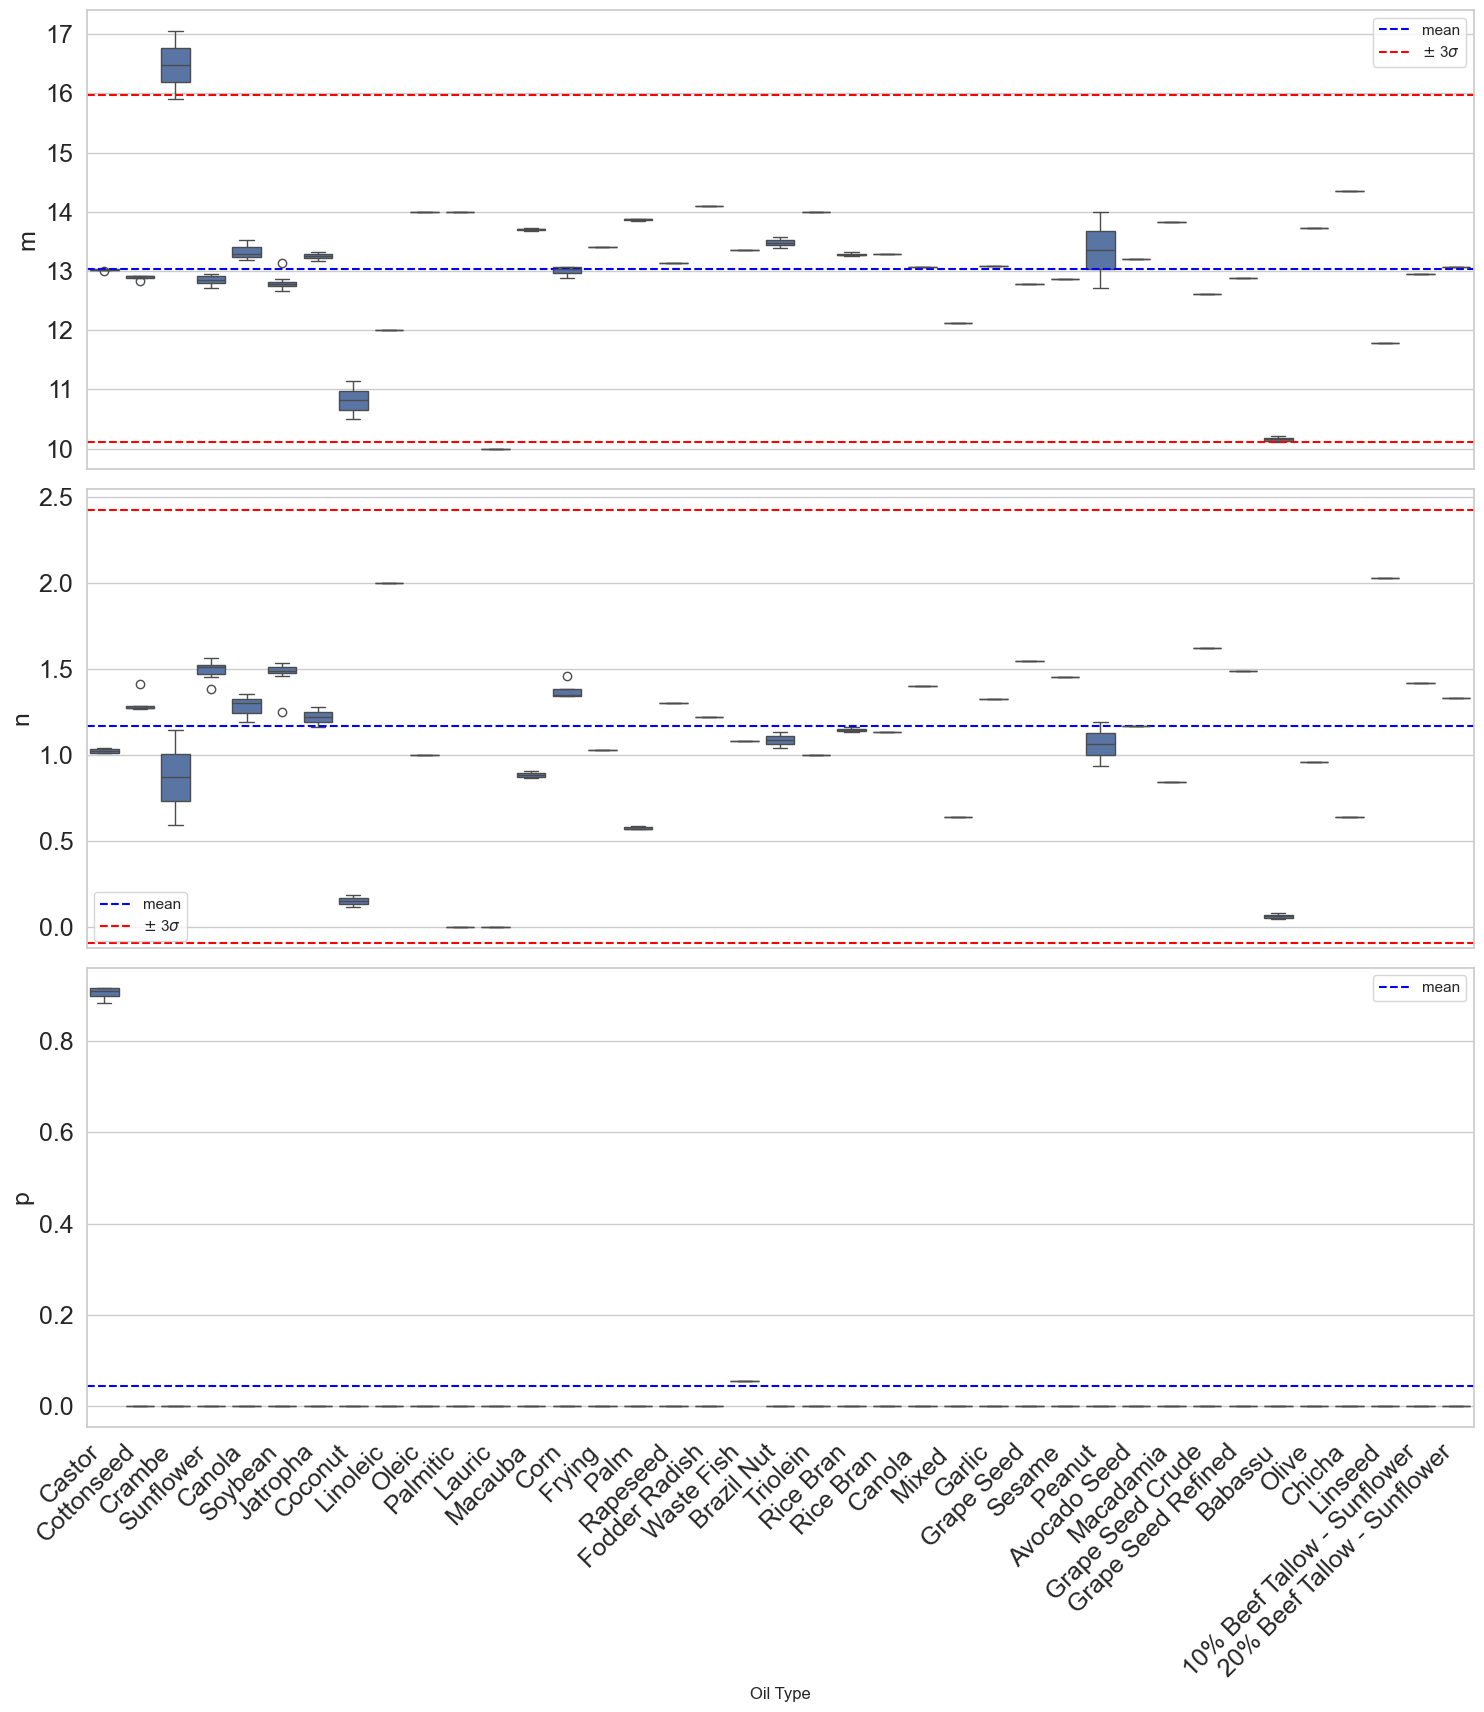

In [176]:

columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)
axes = axes.flatten()

sns.boxplot(x='Source', y="m", data=df_pandas, ax=axes[0])
axes[0].set_xlabel('Oil Type')
axes[0].set_ylabel("m", fontsize=18)
axes[0].axhline(y=stats_m["mean"], color="blue", linestyle="--", label="mean")
axes[0].axhline(y=stats_m["mean"] + stats_m["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[0].axhline(y=stats_m["mean"] - stats_m["std"]*3, color="red", linestyle="--")
axes[0].tick_params(axis='both', labelsize=18)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend()

sns.boxplot(x='Source', y="n", data=df_pandas, ax=axes[1])
axes[1].set_xlabel('Oil Type')
axes[1].set_ylabel("n", fontsize=18)
axes[1].axhline(y=stats_n["mean"], color="blue", linestyle="--", label="mean")
axes[1].axhline(y=stats_n["mean"] + stats_n["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[1].axhline(y=stats_n["mean"] - stats_n["std"]*3, color="red", linestyle="--")
axes[1].tick_params(axis='both', labelsize=18)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend()

sns.boxplot(x='Source', y="p", data=df_pandas, ax=axes[2])
axes[2].set_xlabel('Oil Type')
axes[2].set_ylabel("p", fontsize=18)
axes[2].axhline(y=stats_p["mean"], color="blue", linestyle="--", label="mean")
plt.setp(axes[2].get_xticklabels(), rotation=45, ha='right')
axes[2].legend()
axes[2].tick_params(axis='both', labelsize=18)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(f'Figure_4.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
plt.show()

In [177]:
refined_data = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
raw_data = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx")

In [178]:
raw_data = raw_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [179]:
raw_data.group_by(["Ref", "Sub Ref", "Temperature (K)", "Type Alcohol"]).len()

Ref,Sub Ref,Temperature (K),Type Alcohol,len
i64,str,f64,i64,u32
27,"""b""",303.15,1,3
47,"""c""",318.15,0,2
56,"""a""",298.15,1,5
56,"""b""",298.15,1,5
27,"""a""",303.15,2,9
…,…,…,…,…
51,"""a""",303.15,2,4
27,"""a""",318.15,2,9
47,"""b""",313.15,1,1


In [180]:
comps_MW = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx")

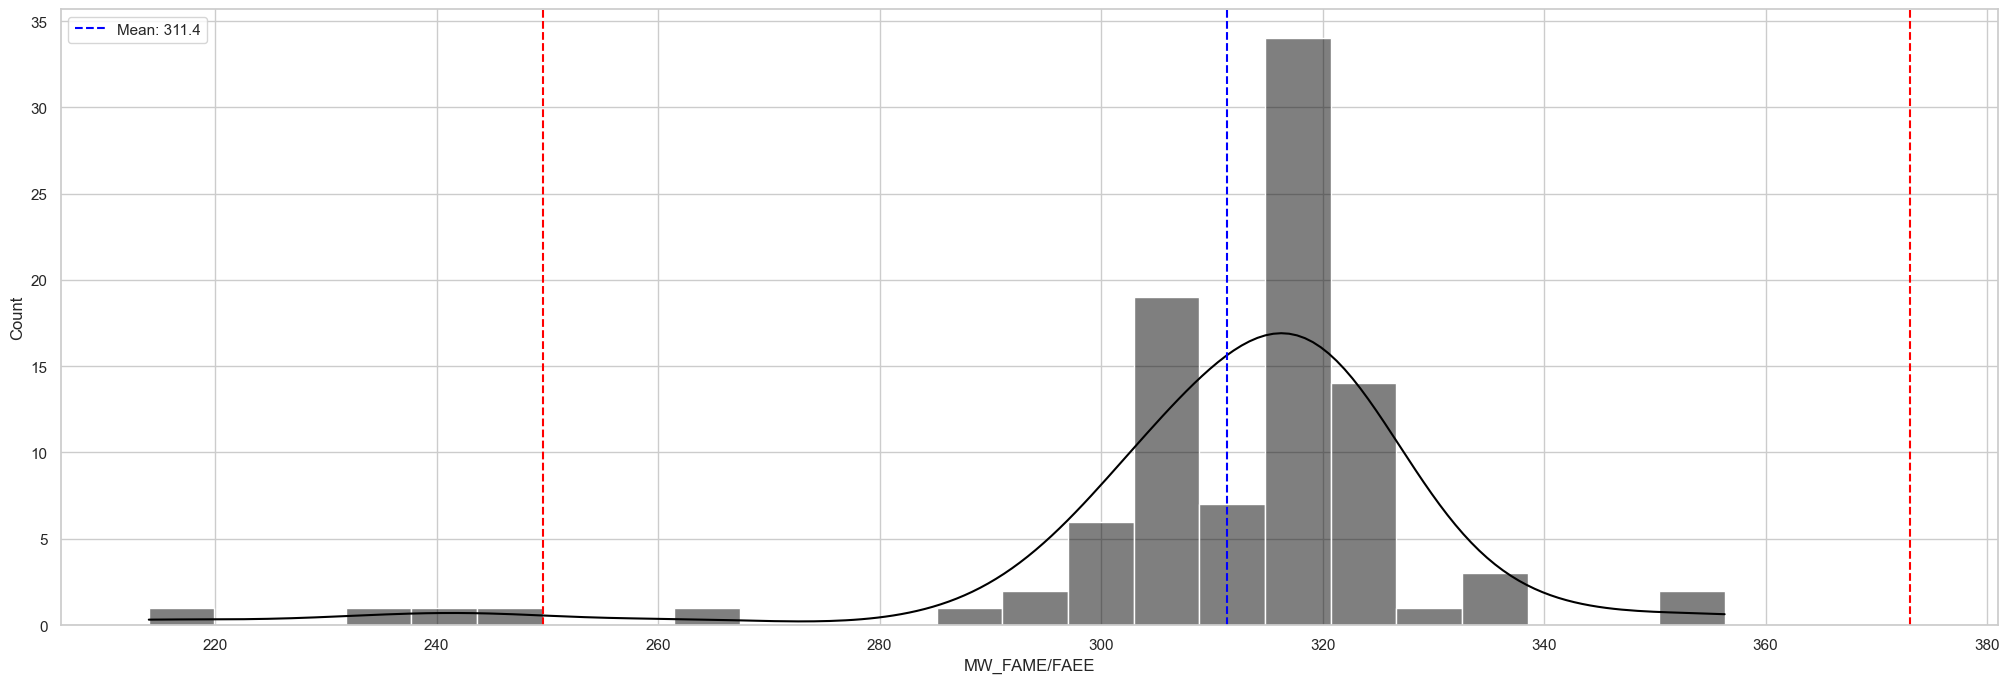

In [181]:
mean_FAME = comps_MW["MW_FAME/FAEE"].mean()
std_FAME = comps_MW["MW_FAME/FAEE"].std()

sns.histplot(x = comps_MW["MW_FAME/FAEE"], color="black", kde=True)
plt.axvline(x=mean_FAME, color="blue", linestyle="--", label = f"Mean: {mean_FAME:.1f}")
plt.axvline(x=mean_FAME + std_FAME*3, color="red", linestyle="--")
plt.axvline(x=mean_FAME - std_FAME*3, color="red", linestyle="--")
plt.legend()
plt.show()

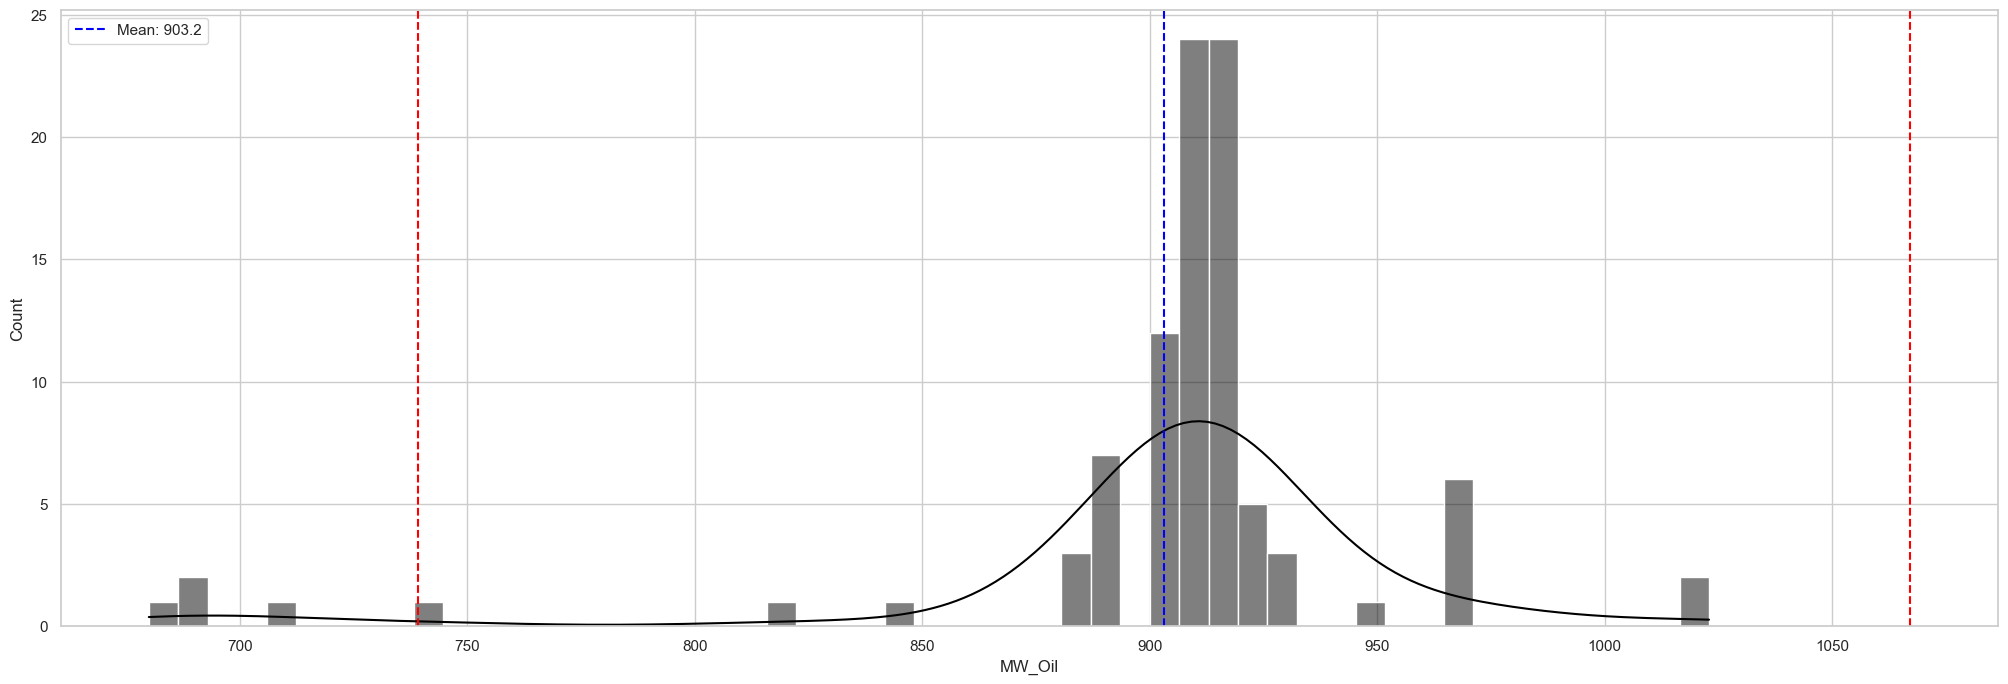

In [182]:
mean_Oil = comps_MW["MW_Oil"].mean()
std_Oil = comps_MW["MW_Oil"].std()
sns.histplot(x = comps_MW["MW_Oil"], color="black", kde=True)
plt.axvline(x=mean_Oil, color="blue", linestyle="--", label = f"Mean: {mean_Oil:.1f}")
plt.axvline(x=mean_Oil + std_Oil*3, color="red", linestyle="--")
plt.axvline(x=mean_Oil - std_Oil*3, color="red", linestyle="--")
plt.legend()
plt.show()

In [183]:
refined_data = refined_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [184]:
refined_data.group_by(["Ref", "Sub Ref", "Temperature (K)", "Type Alcohol"]).len()

Ref,Sub Ref,Temperature (K),Type Alcohol,len
i64,str,f64,i64,u32
55,"""a""",303.2,2,2
35,"""a""",283.15,3,4
26,"""a""",323.15,1,4
27,"""b""",333.15,1,1
31,"""a""",298.15,2,15
…,…,…,…,…
43,"""a""",303.15,1,2
57,"""a""",298.2,2,3
56,"""b""",308.15,1,5


In [185]:
result = refined_data.join(
    comps_MW,
    on=["Ref", "Sub Ref"],
    how="left"
)

result = result.with_columns(
    pl.col('Sub Ref').str.slice(0, 1).alias('Sub Ref')
)

In [186]:
base_columns = [
    'FAME/FAEE',
    'GLYCEROL',
    'ALCOHOL',
    'OIL',
    'DAG',
    'MAG',
    'ACID',
    'WATER'
]

# Create the K_ columns with the condition: if _H is 0, then K_ is 0
for col in base_columns:
    col_l = f"{col}_L"
    col_h = f"{col}_H"
    k_col = f"K_{col}"
    
    # Using when/then/otherwise for conditional logic
    result = result.with_columns(
        pl.when(pl.col(col_h) == 0)
        .then(pl.lit(0))
        .otherwise(np.log10(pl.col(col_h) / pl.col(col_l)))
        .alias(k_col)
    )
    
    


c:\Users\USER\anaconda3\envs\maestria\Lib\site-packages\polars\series\series.py:1411: RuntimeWarning: divide by zero encountered in log10
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


In [187]:
result = result.drop("Type Alcohol_right")

In [188]:
joined_types = result.join(filtered_df, on=["Ref", "Sub Ref"], how="inner")

In [189]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").mean().alias("K_OIL_mean"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_mean
str,f64
"""Cottonseed""",-0.539088
"""Soybean""",-0.618019
"""Palm""",-0.659617
"""Corn""",-0.444498


In [190]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").std().alias("K_OIL_std"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_std
str,f64
"""Cottonseed""",1.595794
"""Palm""",0.960284
"""Corn""",1.289902
"""Soybean""",1.054324


In [191]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").min().alias("K_OIL_min"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_min
str,f64
"""Soybean""",-4.976828
"""Corn""",-2.324807
"""Cottonseed""",-4.960204
"""Palm""",-2.287639


In [192]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").max().alias("K_OIL_max"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_max
str,f64
"""Cottonseed""",1.093462
"""Palm""",0.809108
"""Soybean""",1.242963
"""Corn""",2.095884


In [193]:
with pl.Config(tbl_rows=len(result), tbl_cols=-1):
    print(result.group_by(["Ref", "Sub Ref", "Temperature (K)"], maintain_order=True).agg(pl.col(['K_FAME/FAEE', 'K_GLYCEROL', 'K_ALCOHOL', 'K_OIL', 'K_DAG', 'K_MAG', 'K_ACID','K_WATER']).mean()).write_csv("K_means.csv"))
    print(result.group_by(["Ref", "Sub Ref", "Temperature (K)"], maintain_order=True).agg(pl.col(['K_FAME/FAEE', 'K_GLYCEROL', 'K_ALCOHOL', 'K_OIL', 'K_DAG', 'K_MAG', 'K_ACID','K_WATER']).std()).write_csv("K_std.csv"))
    

None
None


In [194]:
K_means = pl.read_csv("K_means.csv")
K_std = pl.read_csv("K_std.csv")

In [195]:
references = {
    
    '1a': ['B. B. França, F. M. Pinto, F. L. P. Pessoa, and A. M. C. Uller, “Liquid−Liquid Equilibria for Castor Oil Biodiesel + Glycerol + Alcohol,” J Chem Eng Data, vol. 54, no. 9, pp. 2359–2364, Sep. 2009, doi: 10.1021/je800564d.', 
           'Castor oil biodiesel - Methanol - Glycerol'],
    
    '2a': ['F. M. R. Mesquita, A. M. M. Bessa, D. D. de Lima, H. B. de Sant’Ana, and R. S. de Santiago-Aguiar, “Liquid–liquid equilibria of systems containing cottonseed biodiesel+glycerol+ethanol at 293.15, 313.15 and 333.15K,” Fluid Phase Equilib, vol. 318, pp. 51–55, Mar. 2012, doi: 10.1016/j.fluid.2012.01.016', 
           'Cottonseed oil biodiesel - Ethanol - Glycerol'],
    
    '3a': ['R. C. Basso, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium of pseudoternary systems containing glycerol+ethanol+ethylic biodiesel from crambe oil (Crambe abyssinica) at T/K=(298.2, 318.2, 338.2) and thermodynamic modeling,” Fluid Phase Equilib, vol. 333, pp. 55–62, Nov. 2012, doi: 10.1016/j.fluid.2012.07.018.', 
           'Cambre oil biodiesel - Ethanol - Glycerol'],
   
    '4a': ['M. Rostami, S. Raeissi, M. Mahmoodi, and M. Nowroozi, “Liquid–Liquid Equilibria in Biodiesel Production,” J Am Oil Chem Soc, vol. 90, no. 1, pp. 147–154, Jan. 2013, doi: 10.1007/s11746-012-2144-5.',
           'Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '5a': ['M. Rostami, S. Raeissi, M. Mahmoodi, and M. Nowroozi, “Liquid–Liquid Equilibria in Biodiesel Production,” J Am Oil Chem Soc, vol. 90, no. 1, pp. 147–154, Jan. 2013, doi: 10.1007/s11746-012-2144-5.', 
           'Canola oil biodiesel - Methanol - Glycerol'], 
    
    '6a': ['X. Liu, X. Piao, Y. Wang, and S. Zhu, “Liquid–Liquid Equilibrium for Systems of (Fatty Acid Ethyl Esters + Ethanol + Soybean Oil and Fatty Acid Ethyl Esters + Ethanol + Glycerol),” J Chem Eng Data, vol. 53, no. 2, pp. 359–362, Feb. 2008, doi: 10.1021/je700382s.',
           'Soybean oil biodiesel - Ethanol - Glycerol'],  
    
    '7a': ['J. R. F. Silva et al., “Thermophysical properties of biodiesel and related systems: (Liquid + liquid) equilibrium data for Jatropha curcas biodiesel,” J Chem Thermodyn, vol. 58, pp. 467–475, Mar. 2013, doi: 10.1016/j.jct.2012.10.006.',
           'Jatropha oil biodiesel - Methanol - Glycerol'],
    
    '8a': ['M. A. Mazutti et al., “Thermophysical properties of biodiesel and related systems: (Liquid + liquid) equilibrium data for soybean biodiesel,” J Chem Thermodyn, vol. 58, pp. 83–94, Mar. 2013, doi: 10.1016/j.jct.2012.10.026.',
           'Soybean oil biodiesel - Methanol - Glycerol'],
    
    '9a': ['A. B. Machado, Y. C. Ardila, L. H. de Oliveira, M. Aznar, and M. R. Wolf Maciel, “Liquid–Liquid Equilibria in Ternary and Quaternary Systems Present in Biodiesel Production from Soybean Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 57, no. 5, pp. 1417–1422, May 2012, doi: 10.1021/je201243u.',
           'Soybean oil biodiesel - Ethanol - Glycerol'],
    
    '10a': ['F. M. R. Mesquita, F. X. Feitosa, N. E. Sombra, R. S. de Santiago-Aguiar, and H. B. de Sant’Ana, “Liquid–Liquid Equilibrium for Ternary Mixtures of Biodiesel (Soybean or Sunflower) + Glycerol + Ethanol at Different Temperatures,” J Chem Eng Data, vol. 56, no. 11, pp. 4061–4067, Nov. 2011, doi: 10.1021/je200340x.',
            'Soybean oil biodiesel - Ethanol - Glycerol'],
    
    '10b': ['F. M. R. Mesquita, F. X. Feitosa, N. E. Sombra, R. S. de Santiago-Aguiar, and H. B. de Sant’Ana, “Liquid–Liquid Equilibrium for Ternary Mixtures of Biodiesel (Soybean or Sunflower) + Glycerol + Ethanol at Different Temperatures,” J Chem Eng Data, vol. 56, no. 11, pp. 4061–4067, Nov. 2011, doi: 10.1021/je200340x.',
            'Sunflower oil biodiesel - Ethanol - Glycerol'],
    
    '11a': ['F. M. R. Mesquita, N. S. Evangelista, H. B. de Sant’Ana, and R. S. de Santiago-Aguiar, “Liquid–Liquid Equilibrium for the Glycerol + Alcohol + Coconut Biodiesel System at Different Temperatures and Atmospheric Pressure,” J Chem Eng Data, vol. 57, no. 12, pp. 3557–3562, Dec. 2012, doi: 10.1021/je300749n.',
            'Coconut oil biodiesel - Ethanol - Glycerol'],
    
    '12a': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Linoleic oil biodiesel - Ethanol - Glycerol'],
    
    '12b': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Oleic oil biodiesel - Ethanol - Glycerol'],
    
    '12c': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Palmitic oil biodiesel - Ethanol - Glycerol'],
    
    '12d': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Lauric oil biodiesel - Ethanol - Glycerol'],
           
    '13a': ['R. C. Basso, C. A. S. da Silva, C. de O. Sousa, A. J. de A. Meirelles, and E. A. C. Batista, “LLE experimental data, thermodynamic modeling and sensitivity analysis in the ethyl biodiesel from macauba pulp oil settling step,” Bioresour Technol, vol. 131, pp. 468–475, Mar. 2013, doi: 10.1016/j.biortech.2012.12.190.',
            'Macuba oil biodiesel - Ethanol - Glycerol'],    
    
    '14a': ['H. Zhou, H. Lu, and B. Liang, “Solubility of Multicomponent Systems in the Biodiesel Production by Transesterification of Jatropha c urcas L. Oil with Methanol,” J Chem Eng Data, vol. 51, no. 3, pp. 1130–1135, May 2006, doi: 10.1021/je0600294.',
            'Jatropha oil biodiesel - Methanol - Glycerol'],
    
    '15a': ['M. B. Oliveira, Sérgio. Barbedo, J. I. Soletti, S. H. V. Carvalho, A. J. Queimada, and J. A. P. Coutinho, “Liquid–liquid equilibria for the canola oil biodiesel + ethanol + glycerol system,” Fuel, vol. 90, no. 8, pp. 2738–2745, Aug. 2011, doi: 10.1016/j.fuel.2011.03.017.',
            'Canola oil biodiesel - Methanol - Glycerol'],
    
    '16a': ['M.-J. Lee, Y.-C. Lo, and H.-M. Lin, “Liquid–liquid equilibria for mixtures containing water, methanol, fatty acid methyl esters, and glycerol,” Fluid Phase Equilib, vol. 299, no. 2, pp. 180–190, Dec. 2010, doi: 10.1016/j.fluid.2010.10.010.',
            'Oleic oil biodiesel - Methanol - Glycerol'],
    
    '17a': ['A. B. Machado, Y. C. Ardila, L. H. de Oliveira, M. Aznar, and M. R. Wolf Maciel, “Liquid−Liquid Equilibrium Study in Ternary Castor Oil Biodiesel + Ethanol + Glycerol and Quaternary Castor Oil Biodiesel + Ethanol + Glycerol + NaOH Systems at (298.2 and 333.2) K,” J Chem Eng Data, vol. 56, no. 5, pp. 2196–2201, May 2011, doi: 10.1021/je101235f.',
            'Castor oil biodiesel - Ethanol - Glycerol'],
    
    '18a': ['S. C. Beneti, M. Lanza, M. A. Mazutti, M. H. Kunita, L. Cardozo-Filho, and J. Vladimir Oliveira, “Experimental (liquid+liquid) equilibrium data for ternary and quaternary mixtures of fatty acid methyl and ethyl esters (FAME/FAEE) from soybean oil,” J Chem Thermodyn, vol. 68, pp. 60–70, Jan. 2014, doi: 10.1016/j.jct.2013.08.032.',
            'Soybean oil biodiesel - Methanol - Glycerol'],
    
    '19a': ['M. Rostami, S. Raeissi, M. Ranjbaran, M. Mahmoodi, and M. Nowroozi, “Experimental investigation and modeling of liquid–liquid equilibria in two systems of concern in biodiesel production,” Fluid Phase Equilib, vol. 353, pp. 31–37, Sep. 2013, doi: 10.1016/j.fluid.2013.05.015.',
            'Corn oil biodiesel - Methanol - Glycerol'],
     
    '19b': ['M. Rostami, S. Raeissi, M. Ranjbaran, M. Mahmoodi, and M. Nowroozi, “Experimental investigation and modeling of liquid–liquid equilibria in two systems of concern in biodiesel production,” Fluid Phase Equilib, vol. 353, pp. 31–37, Sep. 2013, doi: 10.1016/j.fluid.2013.05.015.',
            'Frying oil biodiesel - Methanol - Glycerol'],
    
    '20a': ['E. G. de A. Rocha, L. A. Follegatti-Romero, S. Duvoisin, and M. Aznar, “Liquid–liquid equilibria for ternary systems containing ethylic palm oil biodiesel+ethanol+glycerol/water: Experimental data at 298.15 and 323.15K and thermodynamic modeling,” Fuel, vol. 128, pp. 356–365, Jul. 2014, doi: 10.1016/j.fuel.2014.01.074.',
            'Palm oil biodiesel - Ethanol - Glycerol'],
   
    '21a': ['A. L. Esipovich, A. E. Rogozhin, A. S. Belousov, E. A. Kanakov, K. V. Otopkova, and S. M. Danov, “Liquid–liquid equilibrium in the systems FAMEs + vegetable oil + methyl alcohol and FAMEs + glycerol + methyl alcohol,” Fuel, vol. 217, pp. 31–37, Apr. 2018, doi: 10.1016/j.fuel.2017.12.083.',
           'Rapeseed oil biodiesel - Ethanol - Rapeseed oil'],
   
    '22a': ['J. D. S. Serres, D. Soares, M. L. Corazza, N. Krieger, and D. A. Mitchell, “Liquid–liquid equilibrium data and thermodynamic modeling for systems related to the production of ethyl esters of fatty acids from soybean soapstock acid oil,” Fuel, vol. 147, pp. 147–154, May 2015, doi: 10.1016/j.fuel.2015.01.059.',
           'Soybean oil biodiesel - Ethanol - Water'],
   
    '23a': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Crambe oil biodiesel - Ethanol - Water'],     
    
    '23b': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Fodder radish oil biodiesel - Ethanol - Water'],     

    '23c': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Macauba oil biodiesel - Ethanol - Water'],
   
    '24a': ['M. Maghami, J. Yousefi Seyf, S. M. Sadrameli, and A. Haghtalab, “Liquid–liquid phase equilibrium in ternary mixture of waste fish oil biodiesel–methanol–glycerol: Experimental data and thermodynamic modeling,” Fluid Phase Equilib, vol. 409, pp. 124–130, Feb. 2016, doi: 10.1016/j.fluid.2015.09.046.',
           'Waste fish oil biodiesel - Methanol - Glycerol'],      

    '25a': ['J. D. Gonçalves, M. Aznar, and G. R. Santos, “Liquid–liquid equilibrium data for systems containing Brazil nut biodiesel+methanol+glycerin at 303.15K and 323.15K,” Fuel, vol. 133, pp. 292–298, Oct. 2014, doi: 10.1016/j.fuel.2014.05.004.',
           'Brazil nut oil biodiesel - Methanol - Glycerol'],
    
    '26a': ['M. Hakim, H. Abedini Najafabadi, G. Pazuki, and M. Vossoughi, “Novel Approach for Liquid–Liquid Phase Equilibrium of Biodiesel (Canola and Sunflower) + Glycerol + Methanol,” Ind Eng Chem Res, vol. 53, no. 2, pp. 855–864, Jan. 2014, doi: 10.1021/ie4031902.',
            'Canola oil biodiesel - Methanol - Glycerol'],
    
    '26b': ['M. Hakim, H. Abedini Najafabadi, G. Pazuki, and M. Vossoughi, “Novel Approach for Liquid–Liquid Phase Equilibrium of Biodiesel (Canola and Sunflower) + Glycerol + Methanol,” Ind Eng Chem Res, vol. 53, no. 2, pp. 855–864, Jan. 2014, doi: 10.1021/ie4031902.',
            'Sunflower oil biodiesel - Methanol - Glycerol'],

    '27a': ['M. A. Mazutti et al., “Thermophysical properties of biodiesel and related systems: (Liquid+liquid) equilibrium data for castor oil biodiesel,” J Chem Thermodyn, vol. 62, pp. 17–26, Jul. 2013, doi: 10.1016/j.jct.2013.02.016.',
            'Castor oil biodiesel - Methanol/Ethanol - Glycerol - Water'],
    
    '28a': ['B. B. França, H. G. D. Villardi, F. L. P. Pessoa, and A. M. C. Uller, “Liquid–Liquid Equilibrium for Compounds of Soybean Ethyl Biodiesel Production by Transesterification,” J Chem Eng Data, vol. 58, no. 7, pp. 1927–1933, Jul. 2013, doi: 10.1021/je301313c.',
            'Soybean oil biodiesel - Ethanol - Glycerol - Water'],
    
    '29a': ['E. Batista, S. Monnerat, L. Stragevitch, C. G. Pina, C. B. Gonçalves, and A. J. A. Meirelles, “Prediction of Liquid−Liquid Equilibrium for Systems of Vegetable Oils, Fatty Acids, and Ethanol,” J Chem Eng Data, vol. 44, no. 6, pp. 1365–1369, Nov. 1999, doi: 10.1021/je9900169.',
            'Triolein - Ethanol - Oleic acid'],
    
    '29b': ['E. Batista, S. Monnerat, L. Stragevitch, C. G. Pina, C. B. Gonçalves, and A. J. A. Meirelles, “Prediction of Liquid−Liquid Equilibrium for Systems of Vegetable Oils, Fatty Acids, and Ethanol,” J Chem Eng Data, vol. 44, no. 6, pp. 1365–1369, Nov. 1999, doi: 10.1021/je9900169.',
            'Corn oil - Ethanol - Oleic acid'],    
    
    '30a': ['C. E. C. Rodrigues, É. C. D. Reipert, A. F. de Souza, P. A. P. Filho, and A. J. A. Meirelles, “Equilibrium data for systems composed by cottonseed oil+commercial linoleic acid+ethanol+water+tocopherols at 298.2K,” Fluid Phase Equilib, vol. 238, no. 2, pp. 193–203, Dec. 2005, doi: 10.1016/j.fluid.2005.09.027.',
            'Refined cottonseed oil - Ethanol - Linoelic acid - Water'],
     
    '30b': ['C. E. C. Rodrigues, É. C. D. Reipert, A. F. de Souza, P. A. P. Filho, and A. J. A. Meirelles, “Equilibrium data for systems composed by cottonseed oil+commercial linoleic acid+ethanol+water+tocopherols at 298.2K,” Fluid Phase Equilib, vol. 238, no. 2, pp. 193–203, Dec. 2005, doi: 10.1016/j.fluid.2005.09.027.',
            'Pretreated cottonseed oil - Ethanol - Linoelic acid - Water'],
    
    '31a': ['C. E. C. Rodrigues, R. Antoniassi, and A. J. A. Meirelles, “Equilibrium Data for the System Rice Bran Oil + Fatty Acids + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 48, no. 2, pp. 367–373, Mar. 2003, doi: 10.1021/je0255978.',
            'Rice bran oil - Ethanol - Oelic acid - Water'],
    
    '32a': ['C. M. Oliveira, B. R. Garavazo, and C. E. C. Rodrigues, “Liquid–liquid equilibria for systems composed of rice bran oil and alcohol-rich solvents: Application to extraction and deacidification of oil,” J Food Eng, vol. 110, no. 3, pp. 418–427, Jun. 2012, doi: 10.1016/j.jfoodeng.2011.12.027.',
            'Rice bran oil - Ethanol - Free Fatty Acids - Water'],
    
    '33a': ['C. B. Gonçalves, E. Batista, and A. J. A. Meirelles, “Liquid−Liquid Equilibrium Data for the System Corn Oil + Oleic Acid + Ethanol + Water at 298.15 K,” J Chem Eng Data, vol. 47, no. 3, pp. 416–420, May 2002, doi: 10.1021/je010273p.',
            'Corn oil - Oleic acid - Ethanol - Water'],
    
    '34a': ['C. B. Gonçalves and A. J. A. Meirelles, “Liquid–liquid equilibrium data for the system palm oil + fatty acids + ethanol + water at 318.2 K,” Fluid Phase Equilib, vol. 221, no. 1–2, pp. 139–150, Jul. 2004, doi: 10.1016/j.fluid.2004.05.002.',
            'Palm oil - Palmitic acid - Ethanol - Water'],
    
    '34b': ['C. B. Gonçalves and A. J. A. Meirelles, “Liquid–liquid equilibrium data for the system palm oil + fatty acids + ethanol + water at 318.2 K,” Fluid Phase Equilib, vol. 221, no. 1–2, pp. 139–150, Jul. 2004, doi: 10.1016/j.fluid.2004.05.002.',
            'Palm oil - Oleic acid - Ethanol - Water'],
    
    '35a': ['E. Batista, S. Monnerat, K. Kato, L. Stragevitch, and A. J. A. Meirelles, “Liquid−Liquid Equilibrium for Systems of Canola Oil, Oleic Acid, and Short-Chain Alcohols,” J Chem Eng Data, vol. 44, no. 6, pp. 1360–1364, Nov. 1999, doi: 10.1021/je990015g.',
            'Canola oil - Oleic acid - Methanol/Ethanol/Propanol'],
    
    '36a': ['G. F. Hirata, C. R. A. Abreu, L. C. B. A. Bessa, M. C. Ferreira, E. A. C. Batista, and A. J. A. Meirelles, “Liquid–liquid equilibrium of fatty systems: A new approach for adjusting UNIFAC interaction parameters,” Fluid Phase Equilib, vol. 360, pp. 379–391, Dec. 2013, doi: 10.1016/j.fluid.2013.10.004.',
            'Mixed oil - Oleic acid - Ethanol'],
    
    '37a': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Garlic oil - Linoleic acid - Ethanol - Water'],
    
    '37b': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Grape seed oil - Linoleic acid - Ethanol - Water'],
    
    '37c': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Sesame oil - Linoleic acid - Ethanol - Water'],
    
    '38a': ['C. E. C. Rodrigues, E. C. D. Peixoto, and A. J. A. Meirelles, “Phase equilibrium for systems composed by refined soybean oil+commercial linoleic acid+ethanol+water, at 323.2K,” Fluid Phase Equilib, vol. 261, no. 1–2, pp. 122–128, Dec. 2007, doi: 10.1016/j.fluid.2007.07.021.',
            'Refined Soybean oil - Linoleic acid - Ethanol - Water'],
    
    '39a': ['C. E. C. Rodrigues and A. J. A. Meirelles, “Extraction of Free Fatty Acids from Peanut Oil and Avocado Seed Oil: Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 53, no. 8, pp. 1698–1704, Aug. 2008, doi: 10.1021/je7007186.', 
            'Peanut oil - Oleic acid - Ethanol - Water'],
    
    '39b': ['C. E. C. Rodrigues and A. J. A. Meirelles, “Extraction of Free Fatty Acids from Peanut Oil and Avocado Seed Oil: Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 53, no. 8, pp. 1698–1704, Aug. 2008, doi: 10.1021/je7007186.', 
            'Avocado Seed oil - Oleic acid - Ethanol - Water'],
    
    '40a': ['M. Mohsen-Nia and A. Khodayari, “De-acidification of sunflower oil by solvent extraction: (Liquid+liquid) equilibrium data at T=(303.15 and 313.15)K,” J Chem Thermodyn, vol. 40, no. 8, pp. 1325–1329, Aug. 2008, doi: 10.1016/j.jct.2008.01.029.',
            'Sunflower oil - Oleic acid - Methanol/Ethanol'],
    
    '41a': ['M. Mohsen‐Nia, H. Modarress, and H. R. Nabavi, “Measuring and Modeling Liquid–Liquid Equilibria for a Soybean Oil, Oleic Acid, Ethanol, and Water System,” J Am Oil Chem Soc, vol. 85, no. 10, pp. 973–978, Oct. 2008, doi: 10.1007/s11746-008-1288-9.',
            'Soybean oil - Oleic acid - Methanol/Ethanol - Water'],
    
    '42a': ['C. E. C. Rodrigues, F. A. Silva, A. Marsaioli, and A. J. A. Meirelles, “Deacidification of Brazil Nut and Macadamia Nut Oils by Solvent Extraction:  Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 50, no. 2, pp. 517–523, Mar. 2005, doi: 10.1021/je049687j.',
            'Brazil Nut oil - Oleic acid - Ethanol - Water'],
    
    '42b': ['C. E. C. Rodrigues, F. A. Silva, A. Marsaioli, and A. J. A. Meirelles, “Deacidification of Brazil Nut and Macadamia Nut Oils by Solvent Extraction:  Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 50, no. 2, pp. 517–523, Mar. 2005, doi: 10.1021/je049687j.',
            'Macadamia Nut oil - Oleic acid - Ethanol - Water'],
    
    '43a': ['M. Mohsen-Nia and Mahdi. Dargahi, “Liquid−Liquid Equilibrium for Systems of (Corn Oil + Oleic Acid + Methanol or Ethanol) at (303.15 and 313.15) K,” J Chem Eng Data, vol. 52, no. 3, pp. 910–914, May 2007, doi: 10.1021/je700051j.',
            'Corn oil - Oleic acid - Methanol/Ethanol'],
    
    '44a': ['G. Sanaiotti, J. S. R. Coimbra, J. C. Gomes, and L. A. Minim, “Liquid−Liquid Equilibrium for Systems Composed of Grape Seed Oil + Oleic Acid + Ethanol + Water at (283.2, 290.7, and 298.2) K,” J Chem Eng Data, vol. 53, no. 7, pp. 1492–1497, Jul. 2008, doi: 10.1021/je800034c.',
            'Crude grape seed oil - Oleic acid - Ethanol - Water'],
    
    '44b': ['G. Sanaiotti, J. S. R. Coimbra, J. C. Gomes, and L. A. Minim, “Liquid−Liquid Equilibrium for Systems Composed of Grape Seed Oil + Oleic Acid + Ethanol + Water at (283.2, 290.7, and 298.2) K,” J Chem Eng Data, vol. 53, no. 7, pp. 1492–1497, Jul. 2008, doi: 10.1021/je800034c.',
            'Refined grape seed oil - Oleic acid - Ethanol - Water'],
    
    '45a': ['M. Mohsen‐Nia, H. Modarress, and H. R. Nabavi, “Measuring and Modeling Liquid–Liquid Equilibria for a Soybean Oil, Oleic Acid, Ethanol, and Water System,” J Am Oil Chem Soc, vol. 85, no. 10, pp. 973–978, Oct. 2008, doi: 10.1007/s11746-008-1288-9.', 
            'Soybean oil - Oleic acid - Ethanol - Water'],
    
    '46a': ['É. C. D. Reipert, C. E. C. Rodrigues, and A. J. A. Meirelles, “Phase equilibria study of systems composed of refined babassu oil, lauric acid, ethanol, and water at 303.2K,” J Chem Thermodyn, vol. 43, no. 12, pp. 1784–1790, Dec. 2011, doi: 10.1016/j.jct.2011.05.039.',
            'Babassu oil - Lauric acid - Ethanol - Water'],
    
    '47a': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined Palm oil - Ethanol/Methanol - Waterl'],
    
    '47b': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined palm olein - Ethanol/Methanol- Water'],
    
    '47c': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined palm stearin - Ethanol/Methanol- Water'],
    
    '48a': ['Y. C. Ardila, A. B. Machado, G. M. F. Pinto, R. M. Filho, and M. R. W. Maciel, “Liquid–Liquid Equilibrium in Ternary Systems Present in Biodiesel Purification from Soybean Oil and Castor Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 58, no. 3, pp. 605–610, Mar. 2013, doi: 10.1021/je301028r.',
            'Soybean oil biodiesel - Ethanol - Water'],
    
    '48b': ['Y. C. Ardila, A. B. Machado, G. M. F. Pinto, R. M. Filho, and M. R. W. Maciel, “Liquid–Liquid Equilibrium in Ternary Systems Present in Biodiesel Purification from Soybean Oil and Castor Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 58, no. 3, pp. 605–610, Mar. 2013, doi: 10.1021/je301028r.',
            'Castor oil biodiesel - Ethanol - Water'],
    
    '49a': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Soybean oil - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],

    '49b': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Cottonseed oil - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],
    
    '49c': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Rice bran oil - Ethyl oleate - Oleic acid - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],
    
    '50a': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Olive oil - Capric acid - DAG - MAG - Ethanol'],
    
    '50b': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Sunflower oil - DAG - MAG - Ethanol'],  
    
    '50c': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Coconut oil - Caporic ester - Ethanol'],  
    
    '51a': ['J. C. G. Filho et al., “Liquid–Liquid Equilibrium Measurement and Thermodynamic Modeling of the { Sterculia striata Biodiesel + Glycerol + Ethanol} System,” J Chem Eng Data, vol. 66, no. 8, pp. 3293–3299, Aug. 2021, doi: 10.1021/acs.jced.1c00341.',
            'Chicha oil biodiesel - Ethanol - Glycerol'],
     
    '52a': ['A. Asoodeh, F. Eslami, and S. M. Sadrameli, “Liquid–liquid equilibria of systems containing linseed oil biodiesel + methanol + glycerol: Experimental data and thermodynamic modeling,” Fuel, vol. 253, pp. 460–473, Oct. 2019, doi: 10.1016/j.fuel.2019.04.170.',
            'Linseed oil biodiesel - Methanol - Glycerol'], 
    
    '53a': ['I. E. P. Toledo et al., “Liquid–Liquid Equilibrium of the System {Peanut Biodiesel + Glycerol + Ethanol} at Atmospheric Pressure,” J Chem Eng Data, vol. 64, no. 5, pp. 2207–2212, May 2019, doi: 10.1021/acs.jced.8b01185.',
            'Penaut oil biodiesel - Ethanol - Glycerol'], 
     
    '54a': ['J. C. Nunes et al., “Experimental Data and Phase Equilibrium Modeling in Ternary and Pseudoquaternary Systems of Sunflower Oil for Biodiesel Production,” J Chem Eng Data, vol. 64, no. 2, pp. 412–420, Feb. 2019, doi: 10.1021/acs.jced.8b00276.',
            'Refined sunflower oil biodiesel - Methanol - Glycerol - Water'],
    
    '55a': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined soybean oil biodiesel - DAG - MAG - Ethanol'],
    
    '55b': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined cottonseed oil biodiesel - DAG - MAG - Ethanol'],
    
    '55c': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined rice bran oil biodiesel - DAG - MAG - Ethanol'],
    
    '56a': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            'Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '56b': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            '10 % Beef Tallow/Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '56c': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            '20 % Beef Tallow/Sunflower oil biodiesel - Methanol - Glycerol'],     
    
    '57a': ['O. Z. Sampaio Neto, D. Gonçalves, S. de F. Bergara, E. A. C. Batista, and A. J. de A. Meirelles, “Oil extraction from semi-defatted babassu bagasse with ethanol: Liquid-liquid equilibrium and solid-liquid extraction in a single stage,” J Food Eng, vol. 276, p. 109845, Jul. 2020, doi: 10.1016/j.jfoodeng.2019.109845.',
            'Babassu oil - Ethanol - Water'],
}


In [196]:
K_systems = K_means.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [197]:
K_systems_std = K_std.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [198]:
K_systems.write_csv("K_means.csv")
K_systems_std.write_csv("K_std.csv")

In [199]:
reconciled_data = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")

In [200]:
reconciled_data = reconciled_data.with_columns(
    pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref")
)

In [201]:
reconciled_data_systems = reconciled_data.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [202]:
K_systems = K_systems.drop(["Ref", "Sub Ref"])
K_systems_std= K_systems_std.drop(["Ref", "Sub Ref"])
K_systems_mean = K_systems.group_by(["Systems", "Temperature (K)"]).mean()
K_systems_std_mean = K_systems_std.group_by(["Systems", "Temperature (K)"]).mean()

In [203]:
K_systems_mean.write_csv("K_means.csv")
K_systems_std_mean.write_csv("K_std.csv")

In [204]:
with pl.Config(tbl_rows=155, tbl_cols=-1):
    print(K_systems_mean)

shape: (144, 10)
┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ Systems ┆ Tempera ┆ K_FAME/ ┆ K_GLYCE ┆ K_ALCOH ┆ K_OIL   ┆ K_DAG   ┆ K_MAG   ┆ K_ACID  ┆ K_WATE │
│ ---     ┆ ture    ┆ FAEE    ┆ ROL     ┆ OL      ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ R      │
│ str     ┆ (K)     ┆ ---     ┆ ---     ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆ f64     ┆ ---    │
│         ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆         ┆         ┆         ┆         ┆ f64    │
│         ┆ f64     ┆         ┆         ┆         ┆         ┆         ┆         ┆         ┆        │
╞═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ Babassu ┆ 303.2   ┆ 0.0     ┆ 0.0     ┆ 0.65523 ┆ -1.5166 ┆ 0.0     ┆ 0.0     ┆ -0.0377 ┆ 1.1241 │
│ oil -   ┆         ┆         ┆         ┆ 6       ┆ 91      ┆         ┆         ┆ 03      ┆ 33     │
│ Lauric  ┆         ┆         ┆         ┆         ┆         ┆         ┆   

In [205]:
joined_data = reconciled_data_systems.join(K_systems_mean, on=["Systems", "Temperature (K)"], how="full")
joined_data = joined_data.slice(0, -4)

In [206]:
feed = joined_data.select(['FAME/FAEE_F',
 'GLYCEROL_F',
 'ALCOHOL_F',
 'OIL_F',
 'DAG_F',
 'MAG_F',
 'ACID_F',
 'WATER_F']).to_numpy()

light_phase = joined_data.select(['FAME/FAEE_L',
 'GLYCEROL_L',
 'ALCOHOL_L',
 'OIL_L',
 'DAG_L',
 'MAG_L',
 'ACID_L',
 'WATER_L']).to_numpy()

heavy_phase = joined_data.select(['FAME/FAEE_H',
 'GLYCEROL_H',
 'ALCOHOL_H',
 'OIL_H',
 'DAG_H',
 'MAG_H',
 'ACID_H',
 'WATER_H']).to_numpy()

K_means_numpy = joined_data.select([ 'K_FAME/FAEE',
 'K_GLYCEROL',
 'K_ALCOHOL',
 'K_OIL',
 'K_DAG',
 'K_MAG',
 'K_ACID',
 'K_WATER']).to_numpy()

In [207]:
light_phase = np.nan_to_num(light_phase)
heavy_phase = np.nan_to_num(heavy_phase)
K_means_numpy = np.nan_to_num(K_means_numpy)

calculated_light_phase = 2*feed/(1+(10**K_means_numpy))
calculated_light_phase = calculated_light_phase/np.sum(calculated_light_phase, 1).reshape(-1, 1)

calculated_heavy_phase = calculated_light_phase*10**K_means_numpy
calculated_heavy_phase = calculated_heavy_phase/np.sum(calculated_heavy_phase, 1).reshape(-1, 1)

In [208]:
RMSE_light_phase = root_mean_squared_error(light_phase, calculated_light_phase)

In [209]:
RMSE_heavy_phase = root_mean_squared_error(heavy_phase, calculated_heavy_phase)

In [210]:
(RMSE_light_phase + RMSE_heavy_phase)/2

0.059720273534569795

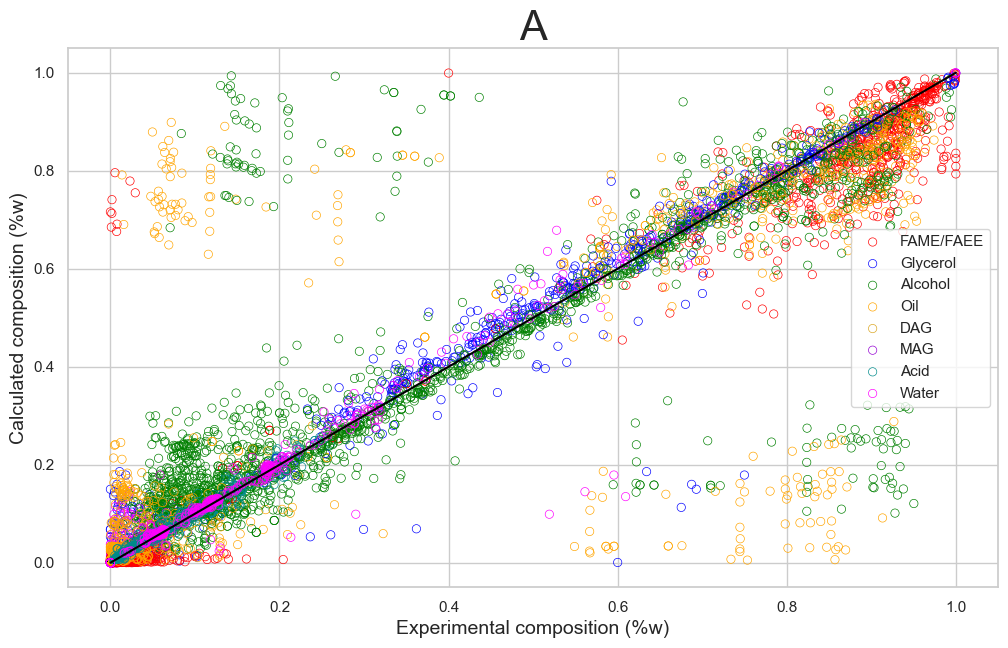

In [212]:
sns.set_theme(rc={'figure.figsize':(12,7)})
sns.set_style("whitegrid")

sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = light_phase[:, 0], y = calculated_light_phase[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")

sns.scatterplot(x = light_phase[:, 1], y = calculated_light_phase[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")

sns.scatterplot(x = light_phase[:, 2], y = calculated_light_phase[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")

sns.scatterplot(x = light_phase[:, 3], y = calculated_light_phase[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")

sns.scatterplot(x = light_phase[:, 4], y = calculated_light_phase[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")

sns.scatterplot(x = light_phase[:, 5], y = calculated_light_phase[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")

sns.scatterplot(x = light_phase[:, 6], y = calculated_light_phase[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")

sns.scatterplot(x = light_phase[:, 7], y = calculated_light_phase[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")

sns.scatterplot(x = heavy_phase[:, 0], y = calculated_heavy_phase[:, 0], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = heavy_phase[:, 1], y = calculated_heavy_phase[:, 1], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = heavy_phase[:, 2], y = calculated_heavy_phase[:, 2], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = heavy_phase[:, 3], y = calculated_heavy_phase[:, 3], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = heavy_phase[:, 4], y = calculated_heavy_phase[:, 4], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = heavy_phase[:, 5], y = calculated_heavy_phase[:, 5], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = heavy_phase[:, 6], y = calculated_heavy_phase[:, 6], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = heavy_phase[:, 7], y = calculated_heavy_phase[:, 7], facecolor = "none", edgecolor = "magenta")

plt.xlabel("Experimental composition (%w)", fontsize=14)
plt.ylabel("Calculated composition (%w)", fontsize=14)
plt.title("A", fontsize=30)
plt.savefig(f'Figure_7A.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
plt.show()


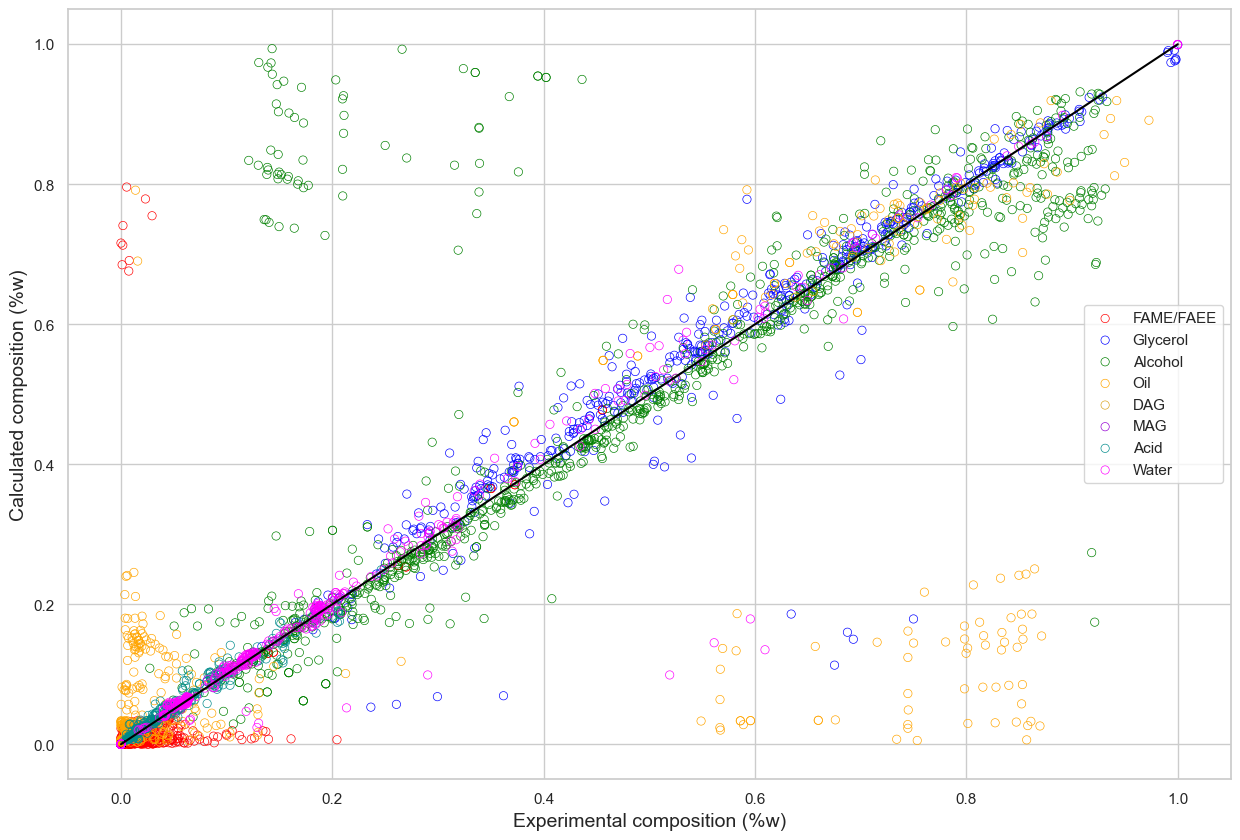

In [213]:
sns.set_theme(rc={'figure.figsize':(15,10)})
sns.set_style("whitegrid")

sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = heavy_phase[:, 0], y = calculated_heavy_phase[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")

sns.scatterplot(x = heavy_phase[:, 1], y = calculated_heavy_phase[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")

sns.scatterplot(x = heavy_phase[:, 2], y = calculated_heavy_phase[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")

sns.scatterplot(x = heavy_phase[:, 3], y = calculated_heavy_phase[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")

sns.scatterplot(x = heavy_phase[:, 4], y = calculated_heavy_phase[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")

sns.scatterplot(x = heavy_phase[:, 5], y = calculated_heavy_phase[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")

sns.scatterplot(x = heavy_phase[:, 6], y = calculated_heavy_phase[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")

sns.scatterplot(x = heavy_phase[:, 7], y = calculated_heavy_phase[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")

plt.xlabel("Experimental composition (%w)", fontsize=14)
plt.ylabel("Calculated composition (%w)", fontsize=14)
plt.show()

In [214]:
k_columns = [
    'K_FAME/FAEE',
    'K_GLYCEROL',
    'K_ALCOHOL',
    'K_OIL',
    'K_DAG',
    'K_MAG', 
    'K_ACID',
    'K_WATER'
]

if isinstance(result, pl.DataFrame):
    pdf = result.to_pandas()
else:
    pdf = result  # Assume it's already pandas

In [215]:
new_columns = ["FAME/FAEE", "Glycerol", "Alcohol", "Oil", "DAG", "MAG", "FA", "Water"]

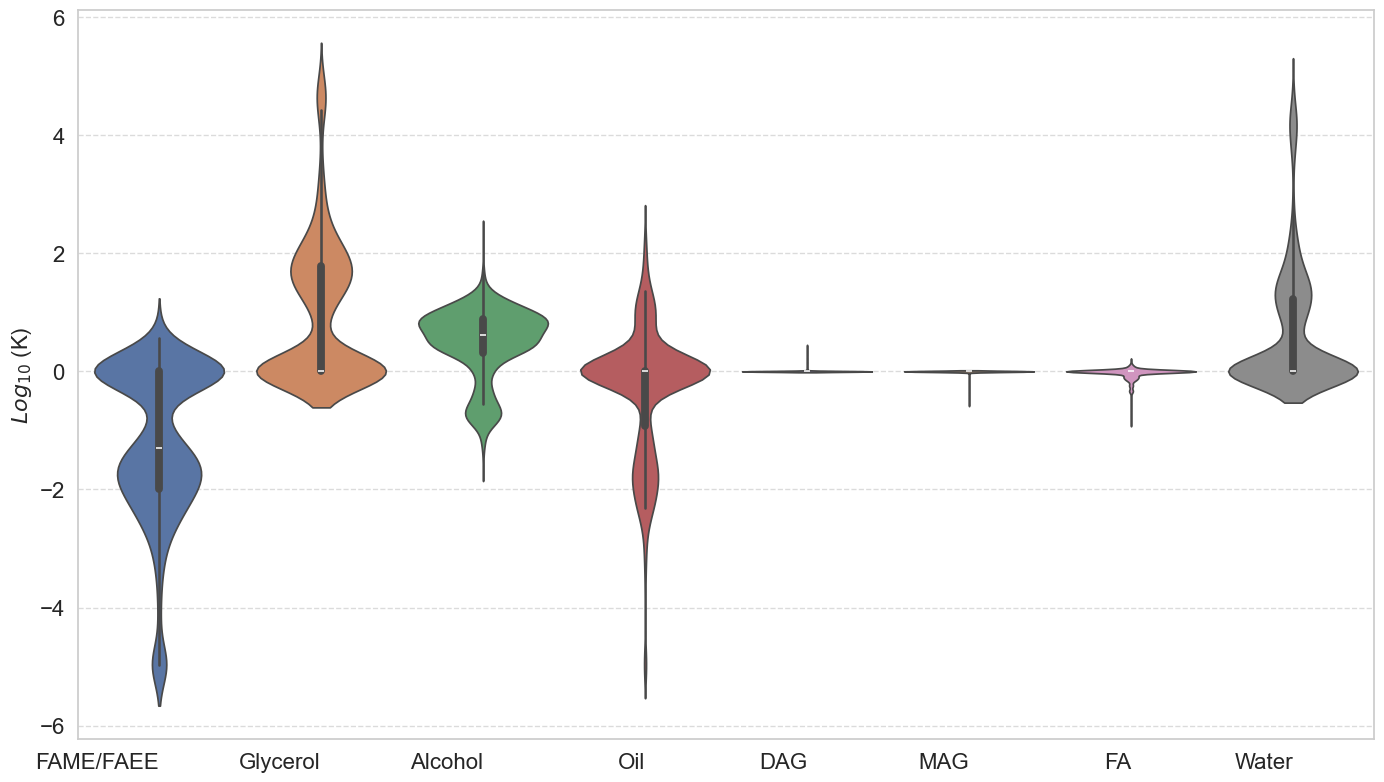

In [216]:
sns.set_style("whitegrid")
k_values_melted = pd.melt(pdf[k_columns], var_name='K Parameter', value_name='Value')

plt.figure(figsize=(14, 8))
sns.violinplot(hue='K Parameter', x = "K Parameter", y='Value', data=k_values_melted, legend=False)
plt.xticks(ticks=range(len(k_columns)), labels=new_columns, ha='right', fontsize=16)
plt.yticks(fontsize=16)
plt.ylabel("$Log_{10}$ (K)", fontsize=16)
plt.xlabel("")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Handle outliers for the combined plot
q1, q3 = np.percentile(k_values_melted['Value'].dropna(), [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
#plt.ylim(0, min(k_values_melted['Value'].max(), upper_limit*1.5))

#plt.ylim(0, 30)

#plt.savefig('k_values_combined_violin.png', dpi=300, bbox_inches='tight')
plt.savefig(f'Figure_5.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
plt.show()



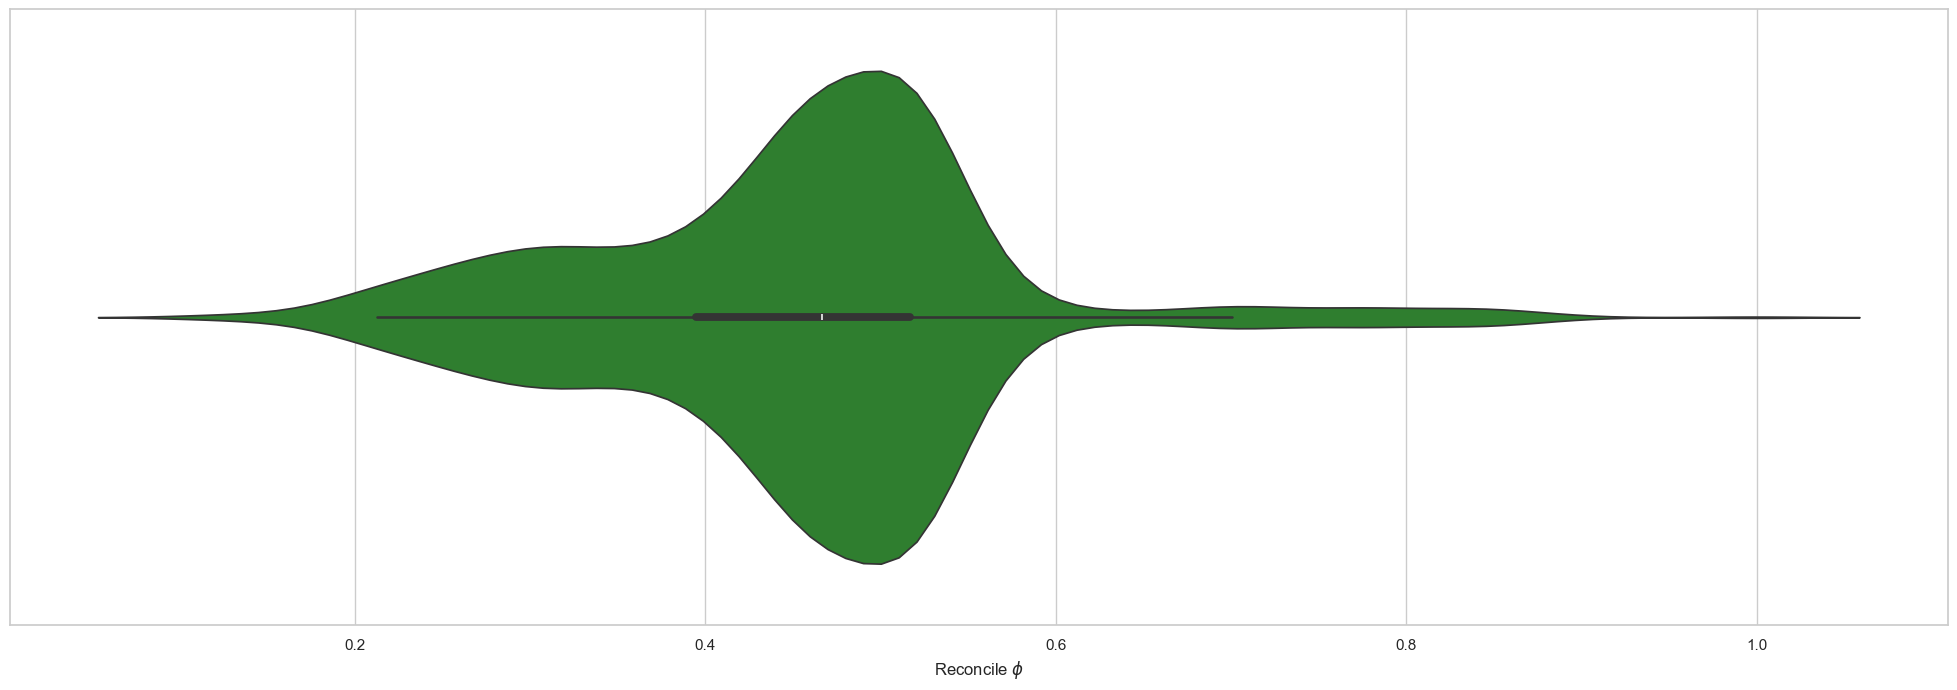

In [108]:
sns.violinplot(data=result,  x="Reconcile phi", color="forestgreen").set(xlabel="Reconcile $\phi$")
plt.show()

In [109]:
k_values_melted.groupby("K Parameter").agg(["mean","median", "std", "min", "max"])

Value                                          
                 mean    median       std        min        max
K Parameter                                                    
K_ACID       0.078609  0.000000  0.233628  -0.391171   2.023775
K_ALCOHOL   -1.103898 -1.430295  1.367583  -5.194970   3.593038
K_DAG       -0.007563  0.000000  0.067665  -1.003187   0.000000
K_FAME/FAEE  2.811167  2.995562  3.075707  -1.311559  11.498690
K_GLYCEROL  -2.296906  0.000000  2.805634 -11.414637   0.000000
K_MAG        0.009658  0.000000  0.087241   0.000000   1.311117
K_OIL        0.778108  0.000000  2.515393  -5.226906  11.486754
K_WATER     -1.532178  0.000000  2.435862 -10.997593   0.000000

In [110]:
K_FAME_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_FAME_corr = K_FAME_df.corr()[["K_FAME/FAEE"]]


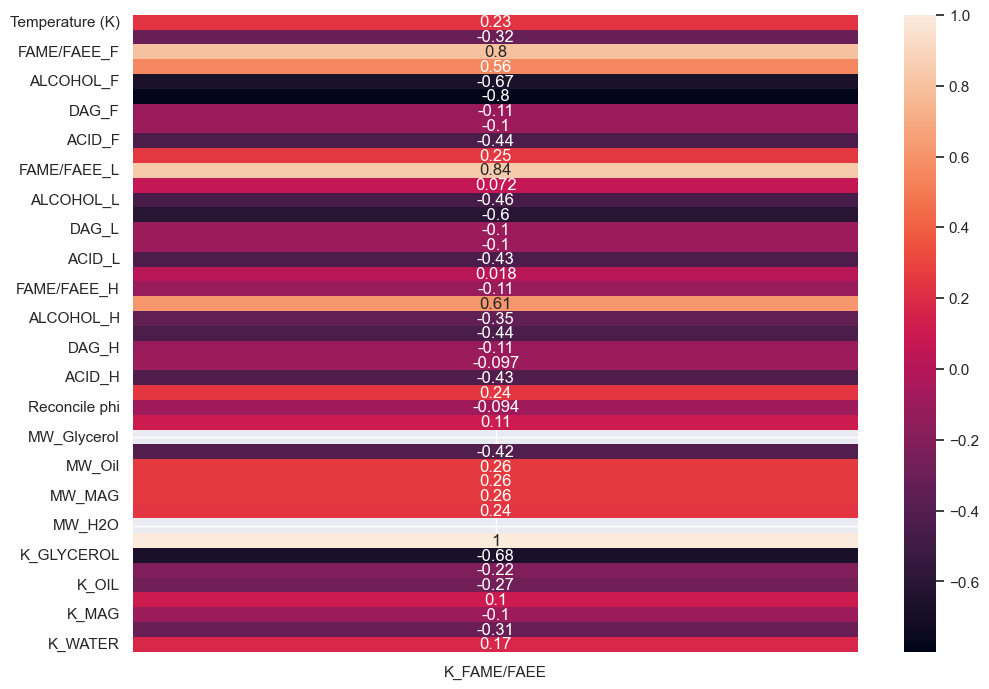

In [111]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_FAME_corr, annot=True)
plt.show()

In [112]:
K_OIL_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_OIL_corr = K_OIL_df.corr()[["K_OIL"]]



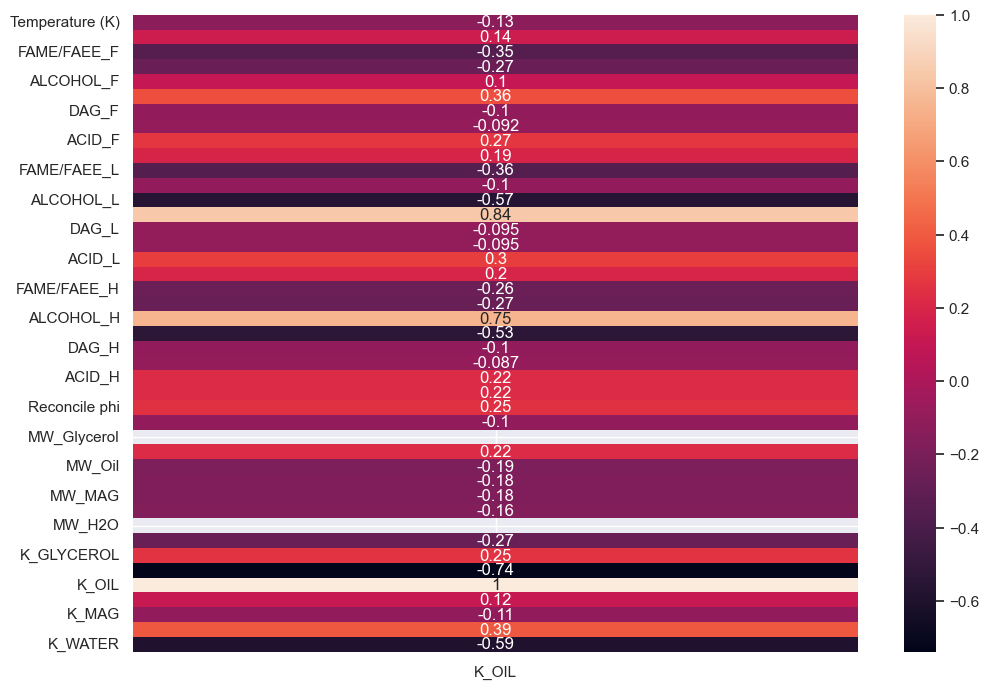

In [113]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_OIL_corr, annot=True)
plt.show()

In [114]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

In [115]:
X = K_FAME_df[["Temperature (K)", "FAME/FAEE_F", "GLYCEROL_F", "ALCOHOL_F"]].to_numpy()
y = K_FAME_df[["K_FAME/FAEE"]].to_numpy()

In [116]:
degree = 2
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

In [117]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
RE = np.mean(abs((y_pred_train - y)/y*100))
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.7309 RMSE: 1.5947


C:\Users\USER\AppData\Local\Temp\ipykernel_42184\3098038206.py:4: RuntimeWarning: divide by zero encountered in divide
  RE = np.mean(abs((y_pred_train - y)/y*100))


In [118]:
np.mean(np.abs((y - y_pred_train)/y * 100))

C:\Users\USER\AppData\Local\Temp\ipykernel_42184\804060054.py:1: RuntimeWarning: divide by zero encountered in divide
  np.mean(np.abs((y - y_pred_train)/y * 100))


inf

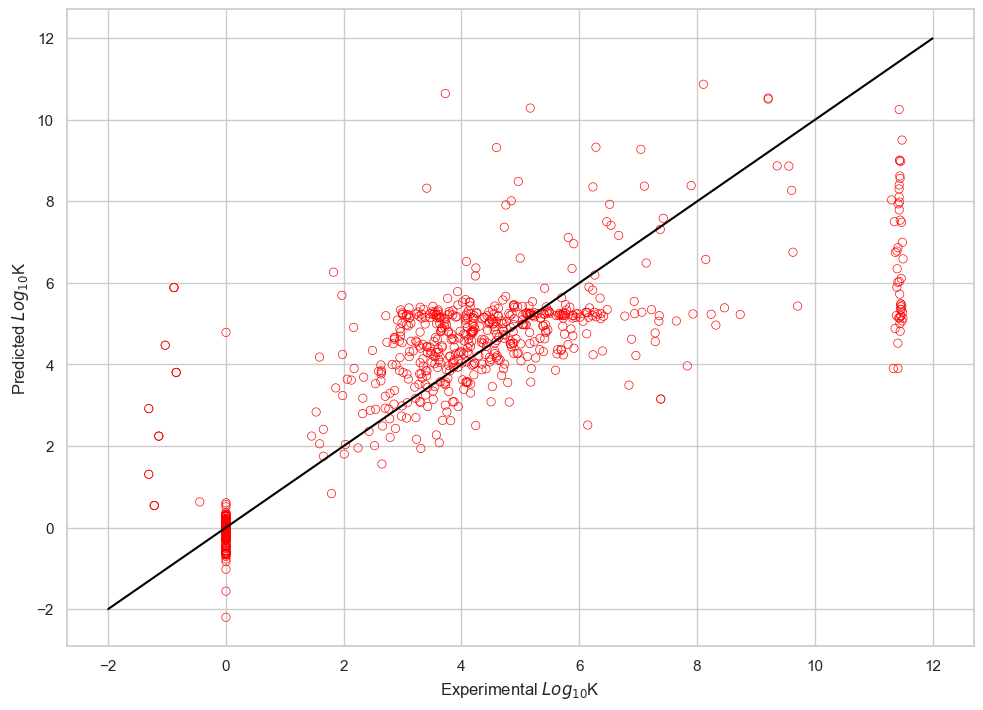

In [119]:
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-2, 12], y = [-2, 12], color = "black")

plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [120]:
X = K_OIL_df[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F", "ALCOHOL_F"]].to_numpy()
y = K_OIL_df[["K_OIL"]].to_numpy()

In [121]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [122]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9272 RMSE: 0.6783


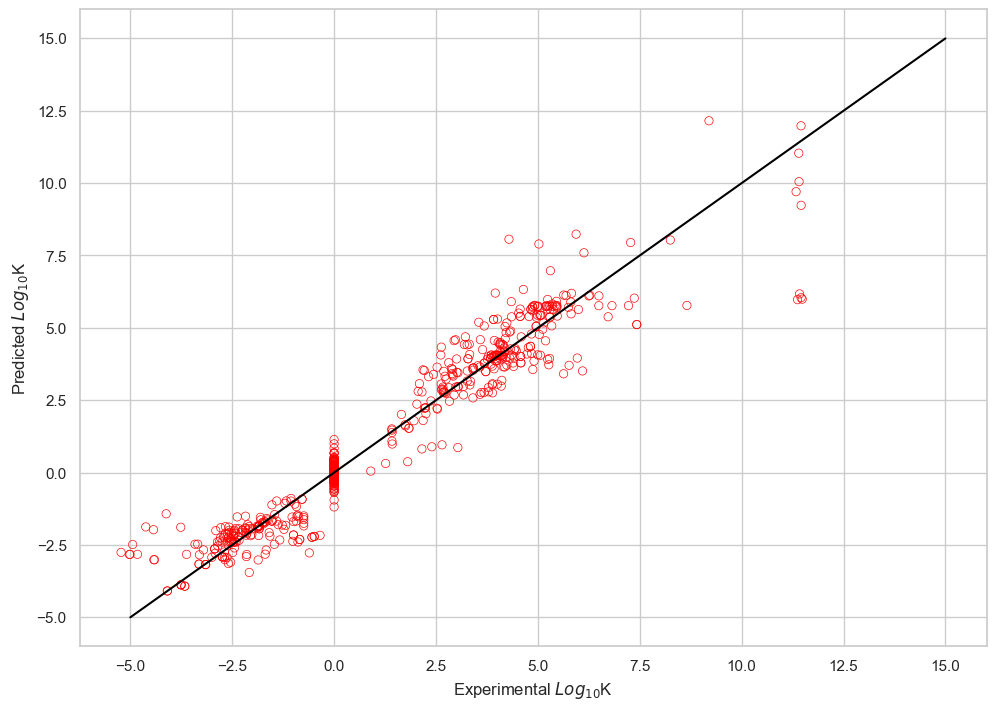

In [123]:
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [124]:
joined_types_pd = joined_types.to_pandas()

In [125]:
joined_types_pd_oils = joined_types_pd[(joined_types_pd["Source"]=="Palm") | (joined_types_pd["Source"]=="Cottonseed") | (joined_types_pd["Source"]=="Corn") | (joined_types_pd["Source"]=="Soybean")]

In [126]:
joined_types_pd_oils = joined_types_pd_oils.drop(["Ref", "Sub Ref", "MAG/DAG Profile?", "Additional FAME Profile?", "Acid mix Profile?", "Source"], axis=1)


In [127]:
joined_types_pd_oils_corr = joined_types_pd_oils.corr()

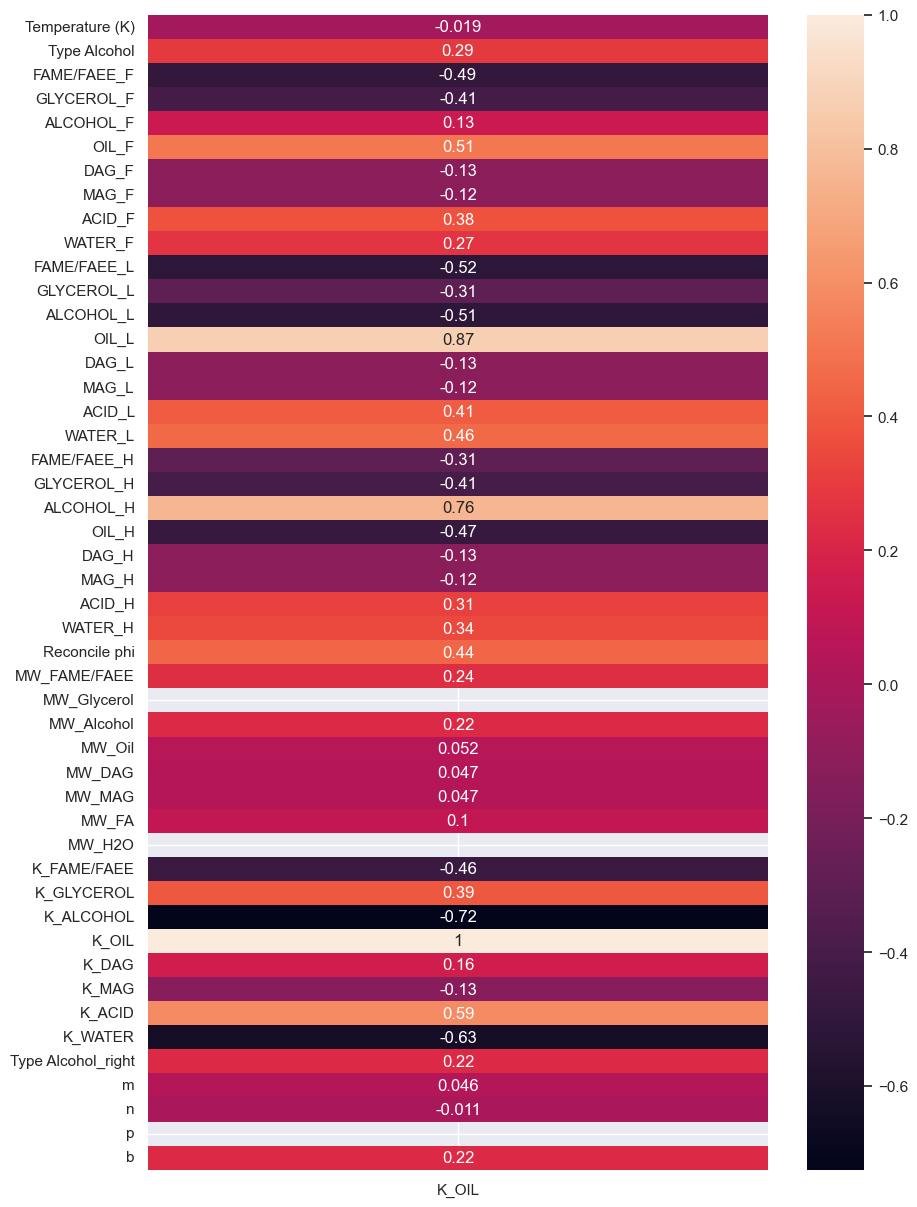

In [128]:
sns.set_theme(rc={'figure.figsize':(10, 15)})
sns.heatmap(joined_types_pd_oils_corr[["K_OIL"]], annot=True)
plt.show()

In [129]:
X = joined_types_pd_oils[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F"]].to_numpy()
y = joined_types_pd_oils[["K_OIL"]].to_numpy()

In [130]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [131]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9578 RMSE: 0.5516


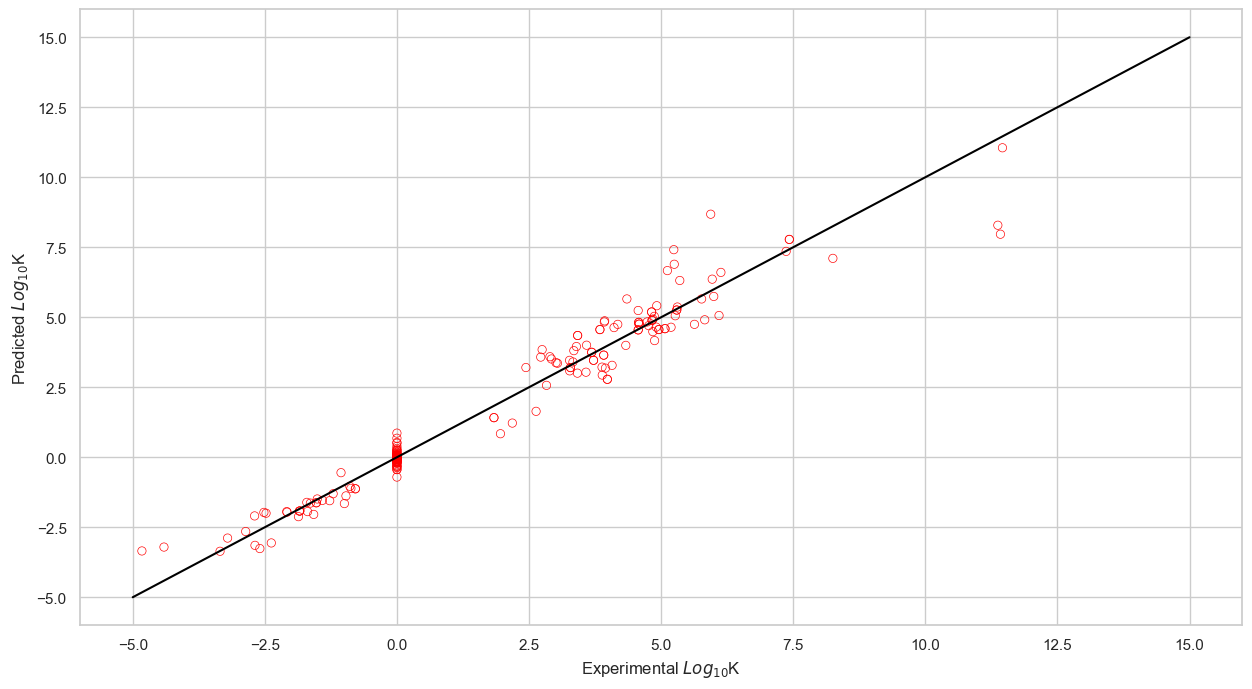

In [149]:
sns.set_theme(rc={'figure.figsize':(15,8)})
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()